# Forecast accuracy

A statistical evaluation of the frozen November 2 forecasts. **Primary:** raw Kalshi Candidate A win probabilities versus the equal-weight Economist/VoteHub Complete mean on the 15 Cook non-Solid races. Candidate A denotes the recorded non-Republican candidate, not a caucus affiliation. Positive paired loss differences mean the first forecast scored worse; lower losses are better.

These rules were written after the election and before scoring, not before outcomes were known. All other comparisons are secondary unless labeled exploratory. This is one election with correlated races. VoteHub Complete incorporates Kalshi prices and expert ratings; the mixed mean is not an independent market-free benchmark. See the [analysis plan](../docs/analysis-plan.md) and [data and scoring guide](../docs/data-and-scoring.md).

In [1]:
from itertools import combinations, product
from statistics import NormalDist
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from congress_scorecard import (
    load_context, select_sample, match_sample, paired_difference,
    probability_score, brier_skill, vote_share_score, brier_loss,
)
from congress_scorecard.data import project_root, sha256
from congress_scorecard.plotting import make_canvas, save_chart, source_colors, graphics_assets
from congress_scorecard.chart_lint import lint_chart

PART = "02_forecast_accuracy"
SOURCES = {
    "p_kalshi": "Kalshi", "p_economist": "Economist", "p_votehub": "VoteHub",
    "p_cook_primary": "Cook", "p_model_mean": "Mixed Mean", "p_blend": "Fixed Blend",
}
SAMPLES = ("all", "non_solid", "robust")
RHOS = (0., .1, .25, .5)
BOOT_SEED, SIM_SEED = 20261104, 20261105
BOOT_DRAWS, SIM_DRAWS = 10000, 20000

In [2]:
def bootstrap_difference(differences, *, draws=BOOT_DRAWS, seed=BOOT_SEED):
    d = np.asarray(differences, dtype=float)
    if not len(d):
        return {"low": None, "high": None, "draws": np.array([])}
    indices = np.random.default_rng(seed).integers(0, len(d), size=(draws, len(d)))
    means = d[indices].mean(axis=1)
    lo, hi = np.quantile(means, [.025, .975])
    return {"low": float(lo), "high": float(hi), "draws": means}


def exact_sign_flip(differences):
    d = np.asarray(differences, dtype=float)
    if not len(d):
        return {"status": "unavailable", "n_pairs": 0, "n_nonzero": 0, "patterns": 0, "p_two_sided": None}
    nonzero = d[d != 0]
    if len(nonzero) > 15:
        raise ValueError("Exact inference is limited to the planned primary sample")
    observed = abs(d.sum())
    tolerance = 1e-12 * max(1., abs(d).sum())
    extreme = sum(abs(np.dot(signs, nonzero)) >= observed - tolerance
                  for signs in product((-1., 1.), repeat=len(nonzero)))
    patterns = 2 ** len(nonzero)
    return {"status": "qualified", "n_pairs": len(d), "n_nonzero": len(nonzero),
            "patterns": patterns, "p_two_sided": extreme / patterns}


def paired_analysis(frame, first, second, *, metric="brier"):
    result = paired_difference(frame, first, second, metric=metric)
    rows = result.per_race
    boot = bootstrap_difference(rows.difference.to_numpy()) if len(rows) else bootstrap_difference([])
    leave_out = []
    if len(rows) >= 2:
        for race in rows.index:
            remaining = rows.drop(index=race)
            weight = remaining._weight / remaining._weight.sum()
            gap = float(np.dot(remaining.difference, weight))
            leave_out.append({"race_id": race, "leave_one_out": gap,
                              "change_from_full": gap - result.value})
    summary = result.summary() | {"first": first, "second": second, "metric": metric,
                                  "low": boot["low"], "high": boot["high"],
                                  "n_nonzero": int(rows.difference.ne(0).sum()) if len(rows) else 0}
    return summary, rows, pd.DataFrame(leave_out), boot["draws"]


def latent_draws(n, *, draws=SIM_DRAWS, seed=SIM_SEED):
    rng = np.random.default_rng(seed)
    return rng.standard_normal((draws, 1)), rng.standard_normal((draws, n))


def copula_outcomes(probabilities, rho, shared, residual):
    p = np.asarray(probabilities, dtype=float)
    if not 0 <= rho <= 1 or np.any(~np.isfinite(p)) or np.any((p < 0) | (p > 1)):
        raise ValueError("Finite probabilities and rho in [0, 1] required")
    if residual.shape[1] != len(p) or shared.shape != (len(residual), 1):
        raise ValueError("Latent draws must match the probability vector")
    nd = NormalDist()
    quantiles = np.array([-np.inf if v == 0 else np.inf if v == 1 else nd.inv_cdf(float(v)) for v in p])
    return np.sqrt(rho) * shared + np.sqrt(1 - rho) * residual <= quantiles


def spiegelhalter(probabilities, outcomes):
    p, y = np.asarray(probabilities, dtype=float), np.asarray(outcomes, dtype=float)
    variance = np.sum((1 - 2 * p) ** 2 * p * (1 - p))
    if not len(p) or variance == 0:
        return None
    return float(np.sum((y - p) * (1 - 2 * p)) / np.sqrt(variance))


def calibration(frame, source, shared, residual):
    matched = match_sample(frame, [source])
    rows = matched.rows
    if not len(rows):
        return pd.DataFrame([{"source": source, "status": "unavailable", "n_planned": len(frame), "n_eligible": 0}])
    p, y = rows[source].to_numpy(), rows.y.to_numpy(dtype=float)
    positions = full_frame.index.get_indexer(rows.index)
    observed = float(np.mean((p - y) ** 2))
    records = []
    for rho in RHOS:
        outcomes = copula_outcomes(p, rho, shared, residual[:, positions])
        scores = ((outcomes - p) ** 2).mean(axis=1)
        records.append({"source": source, "rho_latent": rho, "n_planned": len(frame),
                        "n_eligible": len(rows), "observed_brier": observed,
                        "expected_brier": float(np.mean(p * (1 - p))), "simulated_mean": float(scores.mean()),
                        "sd": float(scores.std(ddof=1)), "low": float(np.quantile(scores, .025)),
                        "high": float(np.quantile(scores, .975)),
                        "observed_percentile": float((np.mean(scores < observed) + .5 * np.mean(scores == observed)) * 100),
                        "spiegelhalter_z_independent": spiegelhalter(p, y), "status": "qualified"})
    return pd.DataFrame(records)


def rank_cook_scores(frame, mapping):
    values = {name: probability_score(frame, col).value for col, name in SOURCES.items() if name != "Cook"}
    values["Cook"] = probability_score(frame, "p_cook_" + mapping).value
    return pd.Series(values, dtype=float).rank(method="min")


def longshot_rows(frame):
    rows = match_sample(frame, ["p_kalshi"]).rows
    result = rows[["p_kalshi", "y"]].copy()
    result["tie"] = result.p_kalshi.eq(.5)
    result["longshot_probability"] = np.minimum(result.p_kalshi, 1 - result.p_kalshi)
    result["longshot_won"] = np.where(result.p_kalshi < .5, result.y, 1 - result.y)
    result.loc[result.tie, "longshot_won"] = np.nan
    result["band"] = pd.cut(result.longshot_probability, [0, .05, .10, .25, .5], right=False,
                            labels=["0–<5%", "5–<10%", "10–<25%", "25–<50%"])
    return result

In [3]:
ctx = load_context(PART)
inputs = ctx.inputs
full_frame = inputs.senate
scratch = project_root().parent / "_scratch" / "part-3" / ctx.output_dir.name
scratch.mkdir(parents=True, exist_ok=True)
figure_records, artifact_hashes = [], {}
colors = source_colors()
shared_latent, residual_latent = latent_draws(len(full_frame))


def table(name, frame, *, show=True):
    frame = frame.copy()
    frame["snapshot"] = inputs.snapshot_id
    frame["synthetic"] = inputs.manifest["synthetic"]
    frame.to_csv(ctx.tables_dir / (name + ".csv"), index=False)
    if show:
        concise = frame.drop(columns=["race_ids", "exclusions", "qualifications", "weight_sum", "weighted"], errors="ignore")
        with pd.option_context("display.max_rows", None, "display.max_columns", None):
            display(concise)
    return frame


from matplotlib import get_data_path
from matplotlib.font_manager import FontProperties
from matplotlib.offsetbox import AnnotationBbox, HPacker, TextArea

SYMBOL_PATH = Path(get_data_path()) / "fonts/ttf/DejaVuSans.ttf"
SYMBOL_FONT = FontProperties(fname=str(SYMBOL_PATH))
SYMBOL_FONTS = [{"filename": SYMBOL_PATH.name, "family": SYMBOL_FONT.get_name(),
                 "sha256": sha256(SYMBOL_PATH), "characters": ["ρ"], "role": "rho_symbol"}]
STATE_NAMES = dict(zip(
    "AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY".split(),
    "Alabama|Alaska|Arizona|Arkansas|California|Colorado|Connecticut|Delaware|Florida|Georgia|Hawaii|Idaho|Illinois|Indiana|Iowa|Kansas|Kentucky|Louisiana|Maine|Maryland|Massachusetts|Michigan|Minnesota|Mississippi|Missouri|Montana|Nebraska|Nevada|New Hampshire|New Jersey|New Mexico|New York|North Carolina|North Dakota|Ohio|Oklahoma|Oregon|Pennsylvania|Rhode Island|South Carolina|South Dakota|Tennessee|Texas|Utah|Vermont|Virginia|Washington|West Virginia|Wisconsin|Wyoming".split("|")))
SAMPLE_NAMES = {"all": "All", "non_solid": "Non-Solid", "robust": "Robust"}


def rich_parts(text):
    parts = []
    for i, part in enumerate(str(text).split("ρ")):
        if i:
            parts.append("ρ")
        if part:
            parts.append(part)
    return parts


def text_width(cv, text, size=23, role="body"):
    width = 0.
    for part in rich_parts(text):
        font = SYMBOL_FONT if part == "ρ" else cv.fp(role)
        artist = cv.fig.text(0, 0, part, fontproperties=font, fontsize=size * cv.scale)
        width += artist.get_window_extent(cv.fig.canvas.get_renderer()).width
        artist.remove()
    return width + max(0, len(rich_parts(text)) - 1) * 2 * cv.scale


def rich_text(cv, x, y, text, *, size=23, role="body", color="white", align="left"):
    children = [TextArea(part, textprops={"fontproperties": SYMBOL_FONT if part == "ρ" else cv.fp(role),
                                        "fontsize": size * cv.scale, "color": color})
                for part in rich_parts(text)]
    box = HPacker(children=children, align="baseline", pad=0, sep=1.44 * cv.scale)
    artist = AnnotationBbox(box, (x, y), xycoords="figure pixels", frameon=False, pad=0,
                           box_alignment=({"left": 0, "center": .5, "right": 1}[align], .5))
    cv.fig.add_artist(artist)
    return artist


def chart_canvas(title, subtitle, note):
    if inputs.manifest["synthetic"]:
        source = "Source: SYNTHETIC software fixture; not election findings. " + note
    else:
        source = "Source: Nov. 2 forecasts; DDHQ Nov. 4 snapshot. Preliminary. " + note
    cv = make_canvas(title, subtitle=subtitle, source=source.replace("ρ", "rho"))
    if "ρ" in source:
        original = next(t for t in cv.fig.texts if t.get_text().startswith("Source:"))
        lines = original.get_text().replace("rho", "ρ").splitlines()
        x, y = original.get_position()
        step = original.get_fontsize() * 100 / 72 * 1.2
        for i, line in enumerate(lines):
            rich_text(cv, x * cv.W, y * cv.H + ((len(lines) - 1) / 2 - i) * step,
                      line, size=28 * .72)
        original.remove()
    return cv


def y_labels(cv, ax, labels):
    ax.set_yticks([])
    for i, label in enumerate(labels):
        x, y = ax.transData.transform((ax.get_xlim()[0], i))
        rich_text(cv, x - 16 * cv.scale, y, label, align="right")


def x_title(cv, ax, title):
    ax.set_xlabel(title.replace("ρ", "rho"))
    if "ρ" in title:
        cv.fig.canvas.draw()
        bounds = ax.xaxis.label.get_window_extent(cv.fig.canvas.get_renderer())
        ax.xaxis.label.set_text("")
        rich_text(cv, bounds.x0 + bounds.width / 2, bounds.y0 + bounds.height / 2,
                  title, size=34 * .72, role="emphasis", align="center")


def axes_style(ax):
    from matplotlib.ticker import MaxNLocator
    ax.grid(axis="x", alpha=.15, color="white")
    ax.set_axisbelow(True)
    left, right = ax.get_xlim()
    ticks = MaxNLocator(nbins=5).tick_values(left, right)
    ax.set_xticks(ticks[(ticks >= left) & (ticks <= right)])
    ax.set_xlim(left, right)


def dot_chart(name, title, data, *, label, value, xlabel, note, low=None, high=None,
              color=None, subtitle=None, zero_reference=True, row_guides=False):
    if data.empty:
        return
    data = data.copy().reset_index(drop=True)
    cv = chart_canvas(title, subtitle, note)
    gutter = max(text_width(cv, x) for x in data[label].astype(str)) + 22 * cv.scale
    ax = cv.axes(left_pad=gutter, right_pad=30 * cv.scale, bottom_pad=93, top_pad=8)
    for i, row in data.iterrows():
        ink = row[color] if color else "#80C2FC"
        if low and high:
            line = ax.plot([row[low], row[high]], [i, i], color=ink, linewidth=3)[0]
            np.testing.assert_allclose(line.get_xdata(), [row[low], row[high]])
        mark = ax.scatter([row[value]], [i], color=ink, s=90, zorder=3)
        np.testing.assert_allclose(mark.get_offsets(), [[row[value], i]])
    ax.set_ylim(len(data) - .5, -.5)
    if row_guides:
        for i in range(len(data)):
            ax.axhline(i, color="white", alpha=.12, linewidth=1, zorder=0)
    if zero_reference:
        ax.axvline(0, color="white", alpha=.5, linewidth=1)
    else:
        ax.margins(x=.15)
    x_title(cv, ax, xlabel if zero_reference else xlabel + " (Zoomed Scale)")
    axes_style(ax)
    y_labels(cv, ax, data[label])
    columns = list(dict.fromkeys(c for c in (label, value, low, high, color, "race_id",
                           "n", "n_planned", "n_eligible", "source", "rho_latent") if c and c in data))
    save_figure(name, cv, data[columns])


def difference_bars(name, title, data, *, label, value, xlabel, subtitle, note):
    data = data.sort_values([value, label], kind="stable").reset_index(drop=True)
    cv = chart_canvas(title, subtitle, note)
    gutter = max(text_width(cv, x) for x in data[label]) + 22 * cv.scale
    ax = cv.axes(left_pad=gutter, right_pad=30 * cv.scale, bottom_pad=93, top_pad=8)
    bars = ax.barh(np.arange(len(data)), data[value], height=.58,
                   color=np.where(data[value].gt(0), "#80C2FC", colors["kalshi"]))
    np.testing.assert_allclose([b.get_width() for b in bars], data[value])
    assert all(b.get_x() == 0 for b in bars)
    for i, v in enumerate(data[value]):
        if v == 0:
            ax.annotate("0", (0, i), xytext=(8 * .72, 0), textcoords="offset points",
                        ha="left", va="center", color="white",
                        fontproperties=cv.fp("emphasis"), fontsize=25 * cv.scale)
    ax.axvline(0, color="white", alpha=.7, linewidth=1.5)
    ax.set_ylim(len(data) - .5, -.5)
    ax.margins(x=.05)
    x_title(cv, ax, xlabel)
    axes_style(ax)
    y_labels(cv, ax, data[label])
    save_figure(name, cv, data[[label, value, "race_id"]])


def bar_chart(name, title, subtitle, data, *, label, value, note, color=None):
    if data.empty:
        return
    data = data.copy().reset_index(drop=True)
    cv = chart_canvas(title, subtitle, note)
    gutter = max(text_width(cv, x) for x in data[label]) + 22 * cv.scale
    right = max(text_width(cv, f"{v:.4f}", size=25, role="emphasis") for v in data[value]) + 30
    ax = cv.axes(left_pad=gutter, right_pad=right, bottom_pad=93, top_pad=8)
    ink = data[color].tolist() if color else ["#80C2FC"] * len(data)
    bars = ax.barh(np.arange(len(data)), data[value], height=.48, color=ink)
    np.testing.assert_allclose([b.get_width() for b in bars], data[value])
    ax.set_ylim(len(data) - .5, -.5)
    ax.set_xlim(0, max(float(data[value].max()) * 1.03, .01))
    for i, v in enumerate(data[value]):
        ax.annotate(f"{v:.4f}", (v, i), xytext=(8 * .72, 0), textcoords="offset points",
                    ha="left", va="center", fontproperties=cv.fp("emphasis"), fontsize=25 * cv.scale,
                    color="white", annotation_clip=False)
    x_title(cv, ax, "Brier Loss (Lower Is Better)")
    axes_style(ax)
    y_labels(cv, ax, data[label])
    save_figure(name, cv, data)


def longshot_chart(data):
    data = data.copy().reset_index(drop=True)
    if not data.n.gt(0).any():
        return
    observed = int(data.observed_wins.fillna(0).sum())
    expected = float(data.expected_wins.sum())
    title = ("One Longshot Won Where About Three Were Expected"
             if observed == 1 and round(expected) == 3 else
             f"Longshots Recorded {observed} Wins Against {expected:.2f} Expected")
    subtitle = ("Longshot wins fell below the combined expectation from the recorded probabilities."
                if observed == 1 and observed < expected else
                "Observed and probability-based expected wins are compared within the same eligible races.")
    note = (f"Exploratory: {int(data.n.sum())} races with a favorite. Sparse groups in one election "
            "do not establish systematic overpricing.")
    cv = chart_canvas(title, subtitle, note)
    labels = [f"{r.band} (n={r.n})" for r in data.itertuples()]
    gutter = max(text_width(cv, x) for x in labels) + 22
    value_width = max(text_width(cv, f"{v:.2f}", size=25, role="emphasis")
                      for v in data.expected_wins) + 24
    legend_width = max(text_width(cv, label) for label in ["Observed", "Expected"]) + 38
    right = value_width + legend_width + 48
    ax = cv.axes(left_pad=gutter, right_pad=right, bottom_pad=93, top_pad=60)
    ax.set_ylim(len(data) - .5, -.5)
    maximum = max(data.expected_wins.max(), data.observed_wins.fillna(0).max())
    ax.set_xlim(0, max(1., maximum * 1.08))
    for field, offset, ink in [("observed_wins", -.16, "#EEEAAC"), ("expected_wins", .16, "#80C2FC")]:
        values = data[field].fillna(0)
        bars = ax.barh(np.arange(len(data)) + offset, values, height=.27, color=ink)
        np.testing.assert_allclose([b.get_width() for b in bars], values)
        for i, v in enumerate(values):
            label = f"{int(v)}" if field == "observed_wins" else f"{v:.2f}"
            ax.annotate(label, (v, i + offset), xytext=(8 * .72, 0), textcoords="offset points",
                        ha="left", va="center", color="white", fontproperties=cv.fp("emphasis"),
                        fontsize=25 * cv.scale, annotation_clip=False)
    x_title(cv, ax, "Longshot Wins")
    axes_style(ax)
    y_labels(cv, ax, labels)
    x0, y0, x1, y1 = cv.plot_rect
    rich_text(cv, x0, y1 - 15, f"{observed} Observed {'Win' if observed == 1 else 'Wins'} · {expected:.2f} Expected",
              size=25, role="emphasis")
    # The legend has its own measured right-hand column.
    from matplotlib.lines import Line2D
    bounds = ax.get_window_extent(cv.fig.canvas.get_renderer())
    legend_x = bounds.x1 + value_width + 24
    center_y = (bounds.y0 + bounds.y1) / 2
    for offset, label, ink in [(38, "Observed", "#EEEAAC"), (-38, "Expected", "#80C2FC")]:
        y = center_y + offset * cv.scale
        cv.fig.add_artist(Line2D([legend_x / cv.W, (legend_x + 24) / cv.W], [y / cv.H] * 2,
                                transform=cv.fig.transFigure, color=ink, linewidth=8))
        rich_text(cv, legend_x + 38, y, label, size=23)
    data["observed_total"], data["expected_total"] = observed, expected
    save_figure("07-longshot-pattern", cv, data)


def power_chart(data):
    data = data.loc[data.n.gt(0)].copy()
    if data.empty:
        return
    wider = all(g.sort_values("rho_latent").detectable_gap_80pct.iloc[-1] >=
                g.sort_values("rho_latent").detectable_gap_80pct.iloc[0]
                for _, g in data.groupby(["sample", "design"]))
    title = ("Correlated Races Make Small Accuracy Gaps Harder to Detect" if wider else
             "Dependence Changes the Gap Needed to Distinguish Forecasts")
    subtitle = "Shared movement leaves less independent evidence for detecting small accuracy gaps."
    note = ("ρ = latent correlation: 0 is independent; 0.5 adds shared movement. Binary correlations differ. "
            "Mixed-forecast scenarios; approximate 80% power, two-sided 5% test.")
    cv = chart_canvas(title, subtitle, note)
    x0, y0, x1, y1 = cv.plot_rect
    bottom, top = y0 + 175, y1 - 60
    gap, left = 115, 108
    width = (x1 - x0 - left - gap - 25) / 2
    ceiling = np.ceil(data.detectable_gap_80pct.max() / .02) * .02
    ceiling = max(.02, ceiling)
    for panel, sample in enumerate(["all", "non_solid"]):
        f = data.loc[data["sample"].eq(sample)]
        ax = cv.axes()
        ax.set_position([(x0 + left + panel * (width + gap)) / cv.W, bottom / cv.H,
                         width / cv.W, (top - bottom) / cv.H])
        planned = f.loc[f.design.eq("planned")].sort_values("rho_latent")
        scored = f.loc[f.design.eq("eligible")].sort_values("rho_latent")
        same = (len(planned) == len(scored) and len(planned) > 0 and
                planned.n.iloc[0] == scored.n.iloc[0] and
                np.array_equal(planned.detectable_gap_80pct.to_numpy(), scored.detectable_gap_80pct.to_numpy()))
        series = [(planned, f"Planned = Scored (n={int(planned.n.iloc[0])})", "#80C2FC", "-", "o")] if same else [
            (planned, f"Planned (n={int(planned.n.iloc[0])})", "#80C2FC", "--", "s"),
            (scored, f"Scored (n={int(scored.n.iloc[0])})" if len(scored) else "No Eligible Races", "#EEEAAC", "-", "o")]
        for frame, label, ink, style, marker in series:
            if frame.empty:
                continue
            line = ax.plot(frame.rho_latent, frame.detectable_gap_80pct, color=ink, linestyle=style,
                           marker=marker, markersize=9, linewidth=3)[0]
            np.testing.assert_allclose(line.get_ydata(), frame.detectable_gap_80pct)
            np.testing.assert_allclose(line.get_xdata(), frame.rho_latent)
        ax.set_xlim(-.015, .515)
        ax.set_ylim(0, ceiling)
        ax.set_xticks(RHOS, ["0", "0.1", "0.25", "0.5"])
        ax.set_yticks(np.linspace(0, ceiling, 4))
        ax.grid(alpha=.15, color="white")
        ax.set_axisbelow(True)
        x_title(cv, ax, "Latent Correlation (ρ)")
        if panel == 0:
            ax.set_ylabel("Detectable Brier Gap")
        bounds = ax.get_window_extent(cv.fig.canvas.get_renderer())
        rich_text(cv, bounds.x0 + bounds.width / 2, y1 - 16,
                  "All Races" if sample == "all" else "Non-Solid", size=28, role="emphasis", align="center")
        widths = [52 * cv.scale + text_width(cv, label, size=23) for _, label, _, _, _ in series]
        legend_gap = 32 * cv.scale
        legend_width = sum(widths) + legend_gap * (len(widths) - 1)
        assert legend_width <= bounds.width, "Power legend must fit on one row"
        legend_x = bounds.x0 + (bounds.width - legend_width) / 2
        y = y0 + 40 * cv.scale
        from matplotlib.lines import Line2D
        for (_, label, ink, style, marker), item_width in zip(series, widths):
            cv.fig.add_artist(Line2D([legend_x / cv.W, (legend_x + 35 * cv.scale) / cv.W], [y / cv.H] * 2,
                                    transform=cv.fig.transFigure, color=ink, linestyle=style, linewidth=3))
            rich_text(cv, legend_x + 52 * cv.scale, y, label, size=23)
            legend_x += item_width + legend_gap
    save_figure("09-power-dependence", cv, data)


def save_figure(name, canvas, data):
    assert "\n" not in canvas.fig.texts[1].get_text(), "Subtitle must fit on one line"
    table("plot_" + name, data, show=False)
    paths = save_chart(canvas, name, out_dir=ctx.figures_dir, scratch_dir=scratch)
    lint = lint_chart(canvas, paths["png"])
    (scratch / (name + "_lint.json")).write_text(json.dumps(lint, indent=2), encoding="utf-8")
    if not lint["passed"]:
        raise ValueError(f"Chart lint failed: {name}: {lint['failures']}")
    figure_records.append({"image": name + ".png", "data": "plot_" + name + ".csv", "lint_passed": True,
                           "title": " ".join(canvas.fig.texts[0].get_text().split()),
                           "subtitle": " ".join(canvas.fig.texts[1].get_text().split())})
    artifact_hashes[name + ".png"] = sha256(paths["png"])
    artifact_hashes["plot_" + name + ".csv"] = sha256(ctx.tables_dir / ("plot_" + name + ".csv"))
    from IPython.display import Image
    display(Image(filename=str(paths["png"]), width=960))
    canvas.fig.clear()


coverage = []
for sample in SAMPLES:
    frame = select_sample(full_frame, sample)
    matched = match_sample(frame, ["p_kalshi", "p_model_mean"])
    coverage.append({"sample": sample, "planned": len(frame), "scored": len(matched.rows),
                     "excluded": json.dumps(matched.excluded)})
display(Markdown(f"**Results:** `{inputs.snapshot_id}`. Senate: {inputs.manifest['senate_timestamp']}. "
                 f"**{'SYNTHETIC SOFTWARE FIXTURE — NOT ELECTION FINDINGS' if inputs.manifest['synthetic'] else 'Preliminary real results'}."))
table("coverage", pd.DataFrame(coverage))
for qualification in inputs.diagnostics["qualifications"]:
    print(qualification)
primary_frame = select_sample(full_frame, "non_solid")
primary = paired_difference(primary_frame, "p_kalshi", "p_model_mean")
if primary.value is not None:
    display(Markdown(f"**Primary paired Brier difference: {primary.value:+.6f}; "
                     f"{primary.n_eligible}/{primary.n_planned} planned races scored.** "
                     "Negative favors Kalshi; this realized difference does not establish general superiority."))
else:
    display(Markdown("**Primary result unavailable: no eligible paired outcomes.**"))
coverage_note = f"{primary.n_eligible} of {primary.n_planned} competitive races scored. "

**Results:** `ddhq-20261104-222052-est`. Senate: 2026-11-04T22:05:02.090703-05:00. **Preliminary real results.

,sample,planned,scored,excluded,snapshot,synthetic
0,all,35,33,"{""AK-SEN"": [""missing y"", ""no verified DDHQ cal...",ddhq-20261104-222052-est,False
1,non_solid,15,13,"{""AK-SEN"": [""missing y"", ""no verified DDHQ cal...",ddhq-20261104-222052-est,False
2,robust,11,10,"{""AK-SEN"": [""missing y"", ""no verified DDHQ cal...",ddhq-20261104-222052-est,False


Preliminary results; eligibility varies by metric.
Kalshi recorded probabilities provisionally approved despite unverified price measures and KY contract URL.
Currency volume labels and dollar cutoff unavailable pending unit verification.
Independent caucus evidence contradicts plan assumption; caucus seat/control reporting withheld.


**Primary paired Brier difference: -0.042977; 13/15 planned races scored.** Negative favors Kalshi; this realized difference does not establish general superiority.

## 1. Proper scoring

Brier uses unrounded analysis probabilities without clipping. Log loss uses natural logs, clipped to [0.01, 0.99], alongside its unclipped value; infinity is preserved. Skill is `1 − source loss / reference loss` on the same eligible observations and weights. Cook, constant-confidence, and uniform references are fixed before scoring. The 11-race robustness subset was defined using forecasts under comparison. All non-primary metrics and subsets are secondary. Kalshi A/(A+B) is a separate conditional-probability sensitivity, not a replacement for raw A.

In [4]:
score_records, skill_records = [], []
for sample in SAMPLES:
    frame = select_sample(full_frame, sample)
    for source, label in {**SOURCES, "p_kalshi_normalized": "Kalshi normalized sensitivity"}.items():
        for metric, clip in (("brier", True), ("log", True), ("log", False)):
            r = probability_score(frame, source, metric=metric, clip=clip)
            score_records.append({"sample": sample, "source": label, "metric": metric, "clipped": metric == "log" and clip,
                                  **r.summary()})
        for reference in ("p_cook_primary", "p_constant", "p_uniform"):
            r = brier_skill(frame, source, reference)
            skill_records.append({"sample": sample, "source": label, "reference": reference, **r.summary()})
scores = table("proper-scores", pd.DataFrame(score_records))
skills = table("skill-scores", pd.DataFrame(skill_records))

,sample,source,metric,clipped,value,status,n_planned,n_eligible,snapshot,synthetic
0,all,Kalshi,brier,False,0.038438,qualified,35,33,ddhq-20261104-222052-est,False
1,all,Kalshi,log,True,0.145957,qualified,35,33,ddhq-20261104-222052-est,False
2,all,Kalshi,log,False,0.145621,qualified,35,33,ddhq-20261104-222052-est,False
3,all,Economist,brier,False,0.064085,qualified,35,33,ddhq-20261104-222052-est,False
4,all,Economist,log,True,0.194818,qualified,35,33,ddhq-20261104-222052-est,False
5,all,Economist,log,False,0.194818,qualified,35,33,ddhq-20261104-222052-est,False
6,all,VoteHub,brier,False,0.046542,qualified,35,33,ddhq-20261104-222052-est,False
7,all,VoteHub,log,True,0.156271,qualified,35,33,ddhq-20261104-222052-est,False
8,all,VoteHub,log,False,0.156271,qualified,35,33,ddhq-20261104-222052-est,False
9,all,Cook,brier,False,0.072700,qualified,35,33,ddhq-20261104-222052-est,False


,sample,source,reference,value,status,n_planned,n_eligible,snapshot,synthetic
0,all,Kalshi,p_cook_primary,0.471285,qualified,35,33,ddhq-20261104-222052-est,False
1,all,Kalshi,p_constant,0.485941,qualified,35,33,ddhq-20261104-222052-est,False
2,all,Kalshi,p_uniform,0.846250,qualified,35,33,ddhq-20261104-222052-est,False
3,all,Economist,p_cook_primary,0.118503,qualified,35,33,ddhq-20261104-222052-est,False
4,all,Economist,p_constant,0.142938,qualified,35,33,ddhq-20261104-222052-est,False
5,all,Economist,p_uniform,0.743661,qualified,35,33,ddhq-20261104-222052-est,False
6,all,VoteHub,p_cook_primary,0.359804,qualified,35,33,ddhq-20261104-222052-est,False
7,all,VoteHub,p_constant,0.377551,qualified,35,33,ddhq-20261104-222052-est,False
8,all,VoteHub,p_uniform,0.813831,qualified,35,33,ddhq-20261104-222052-est,False
9,all,Cook,p_cook_primary,0.000000,qualified,35,33,ddhq-20261104-222052-est,False


## 2. Paired comparisons

Differences always subtract the second forecast's loss from the first's. Each comparison uses identical eligible observations and equal weights; per-race contributions sum to the aggregate difference. Dropping one race from both sides and renormalizing weights measures influence, not uncertainty.

The exact primary-only sign-flip calculation assumes independent differences symmetric about zero under the null, stronger than equal expected accuracy. Correlated races undermine that assumption. The 95% paired percentile bootstrap resamples whole races (10,000 replicates; seed 20261104). It is a conditional sensitivity for this election's races, not an interval across national environments. Secondary comparisons have no confirmatory interpretation or multiplicity adjustment.

,sample,value,status,n_planned,n_eligible,first,second,metric,low,high,n_nonzero,snapshot,synthetic
0,all,-0.025647,qualified,35,33,p_kalshi,p_economist,brier,-0.050712,-0.003839,30,ddhq-20261104-222052-est,False
1,all,-0.048862,qualified,35,33,p_kalshi,p_economist,log,-0.107113,0.002867,28,ddhq-20261104-222052-est,False
2,all,-0.008105,qualified,35,33,p_kalshi,p_votehub,brier,-0.018716,-0.000286,30,ddhq-20261104-222052-est,False
3,all,-0.010315,qualified,35,33,p_kalshi,p_votehub,log,-0.034987,0.010204,28,ddhq-20261104-222052-est,False
4,all,-0.034262,qualified,35,33,p_kalshi,p_cook_primary,brier,-0.070102,-0.005043,28,ddhq-20261104-222052-est,False
5,all,-0.079810,qualified,35,33,p_kalshi,p_cook_primary,log,-0.205855,0.010787,26,ddhq-20261104-222052-est,False
6,all,-0.015834,qualified,35,33,p_kalshi,p_model_mean,brier,-0.032313,-0.001922,30,ddhq-20261104-222052-est,False
7,all,-0.027626,qualified,35,33,p_kalshi,p_model_mean,log,-0.066109,0.006151,28,ddhq-20261104-222052-est,False
8,all,-0.006992,qualified,35,33,p_kalshi,p_blend,brier,-0.014715,-0.000391,30,ddhq-20261104-222052-est,False
9,all,-0.012312,qualified,35,33,p_kalshi,p_blend,log,-0.030473,0.003709,28,ddhq-20261104-222052-est,False


,status,n_pairs,n_nonzero,patterns,p_two_sided,snapshot,synthetic
0,qualified,13,13,8192,0.037842,ddhq-20261104-222052-est,False


,race_id,loss_first,loss_second,difference,_weight,contribution,snapshot,synthetic
0,FL-SEN,0.022500,0.010201,0.012299,0.076923,0.000946,ddhq-20261104-222052-est,False
1,GA-SEN,0.000900,0.003192,-0.002292,0.076923,-0.000176,ddhq-20261104-222052-est,False
2,IA-SEN,0.250000,0.387506,-0.137506,0.076923,-0.010577,ddhq-20261104-222052-est,False
3,KS-SEN,0.136900,0.289444,-0.152544,0.076923,-0.011734,ddhq-20261104-222052-est,False
4,ME-SEN,0.078400,0.073984,0.004416,0.076923,0.000340,ddhq-20261104-222052-est,False
5,MI-SEN,0.048400,0.061009,-0.012609,0.076923,-0.000970,ddhq-20261104-222052-est,False
6,MN-SEN,0.005776,0.021462,-0.015686,0.076923,-0.001207,ddhq-20261104-222052-est,False
7,NC-SEN,0.000576,0.000992,-0.000416,0.076923,-0.000032,ddhq-20261104-222052-est,False
8,NE-SEN,0.090000,0.047089,0.042911,0.076923,0.003301,ddhq-20261104-222052-est,False
9,NH-SEN,0.003969,0.010816,-0.006847,0.076923,-0.000527,ddhq-20261104-222052-est,False


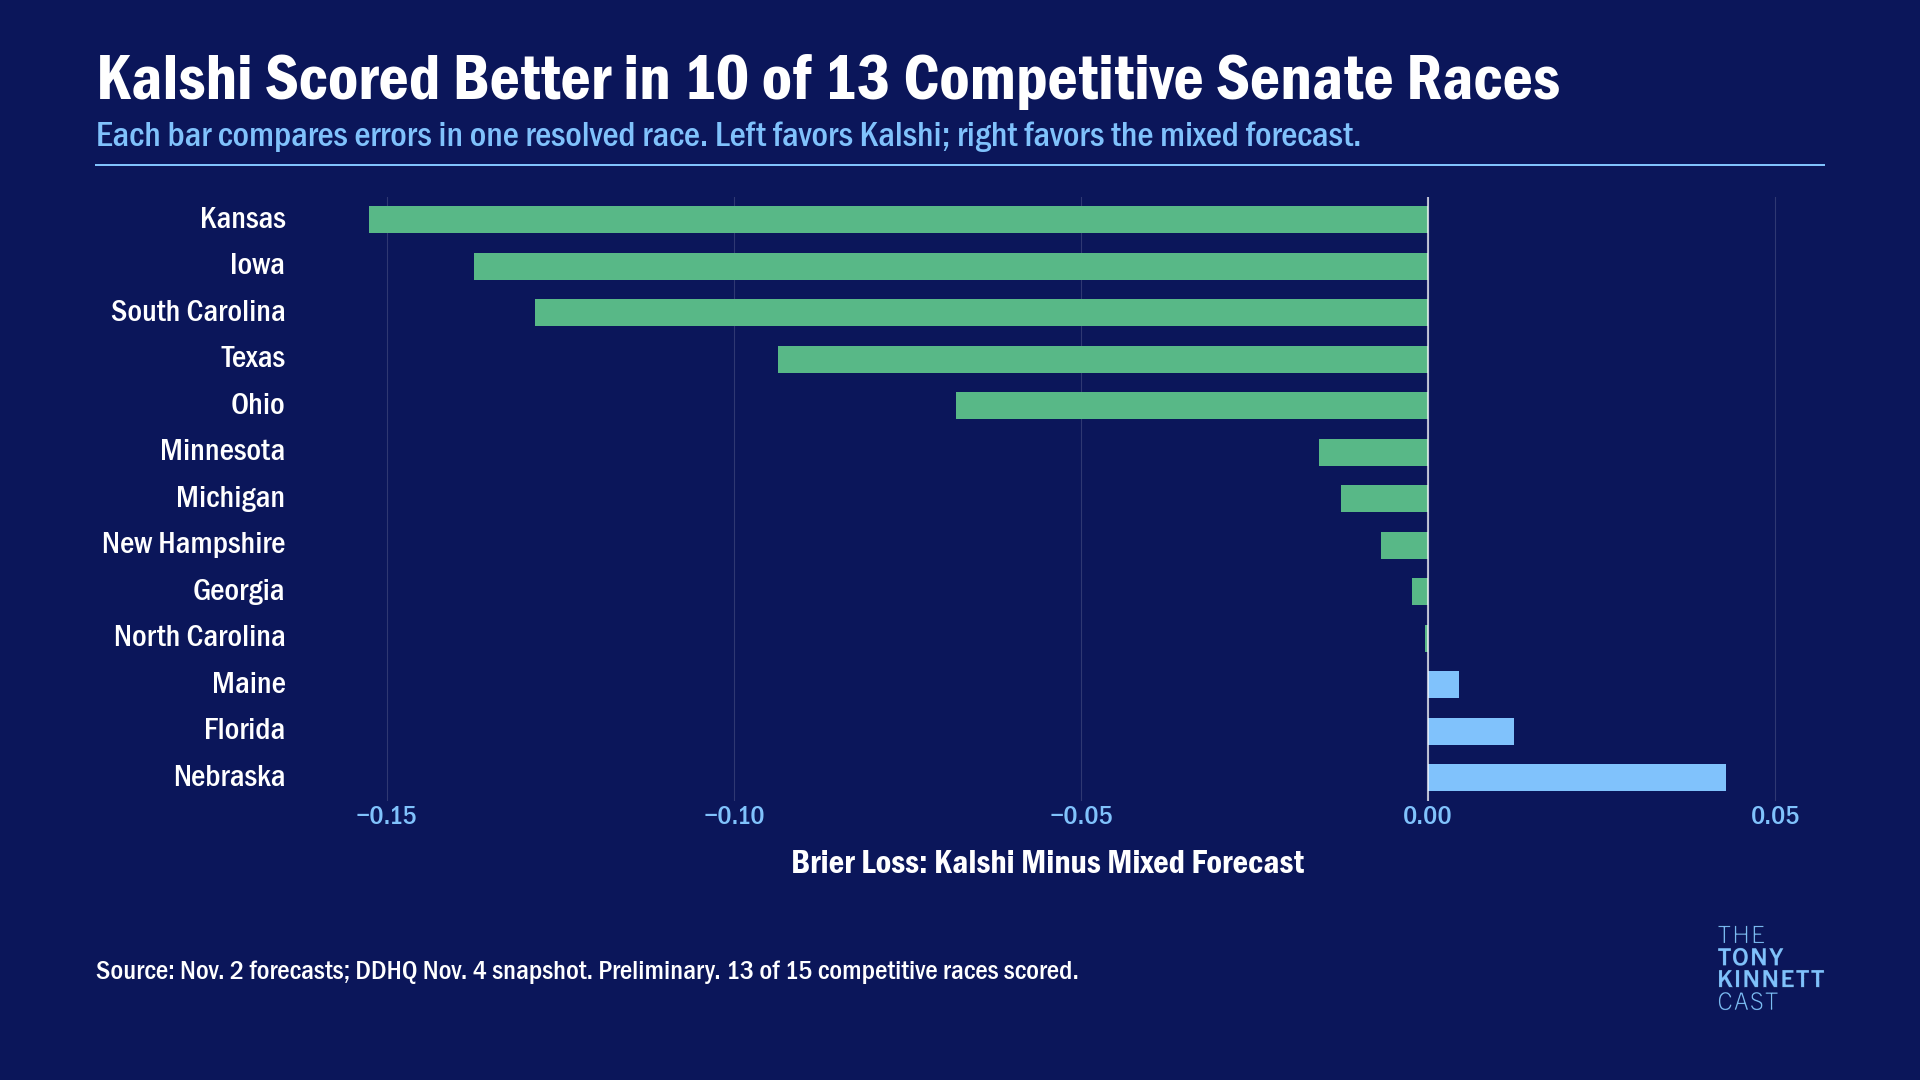

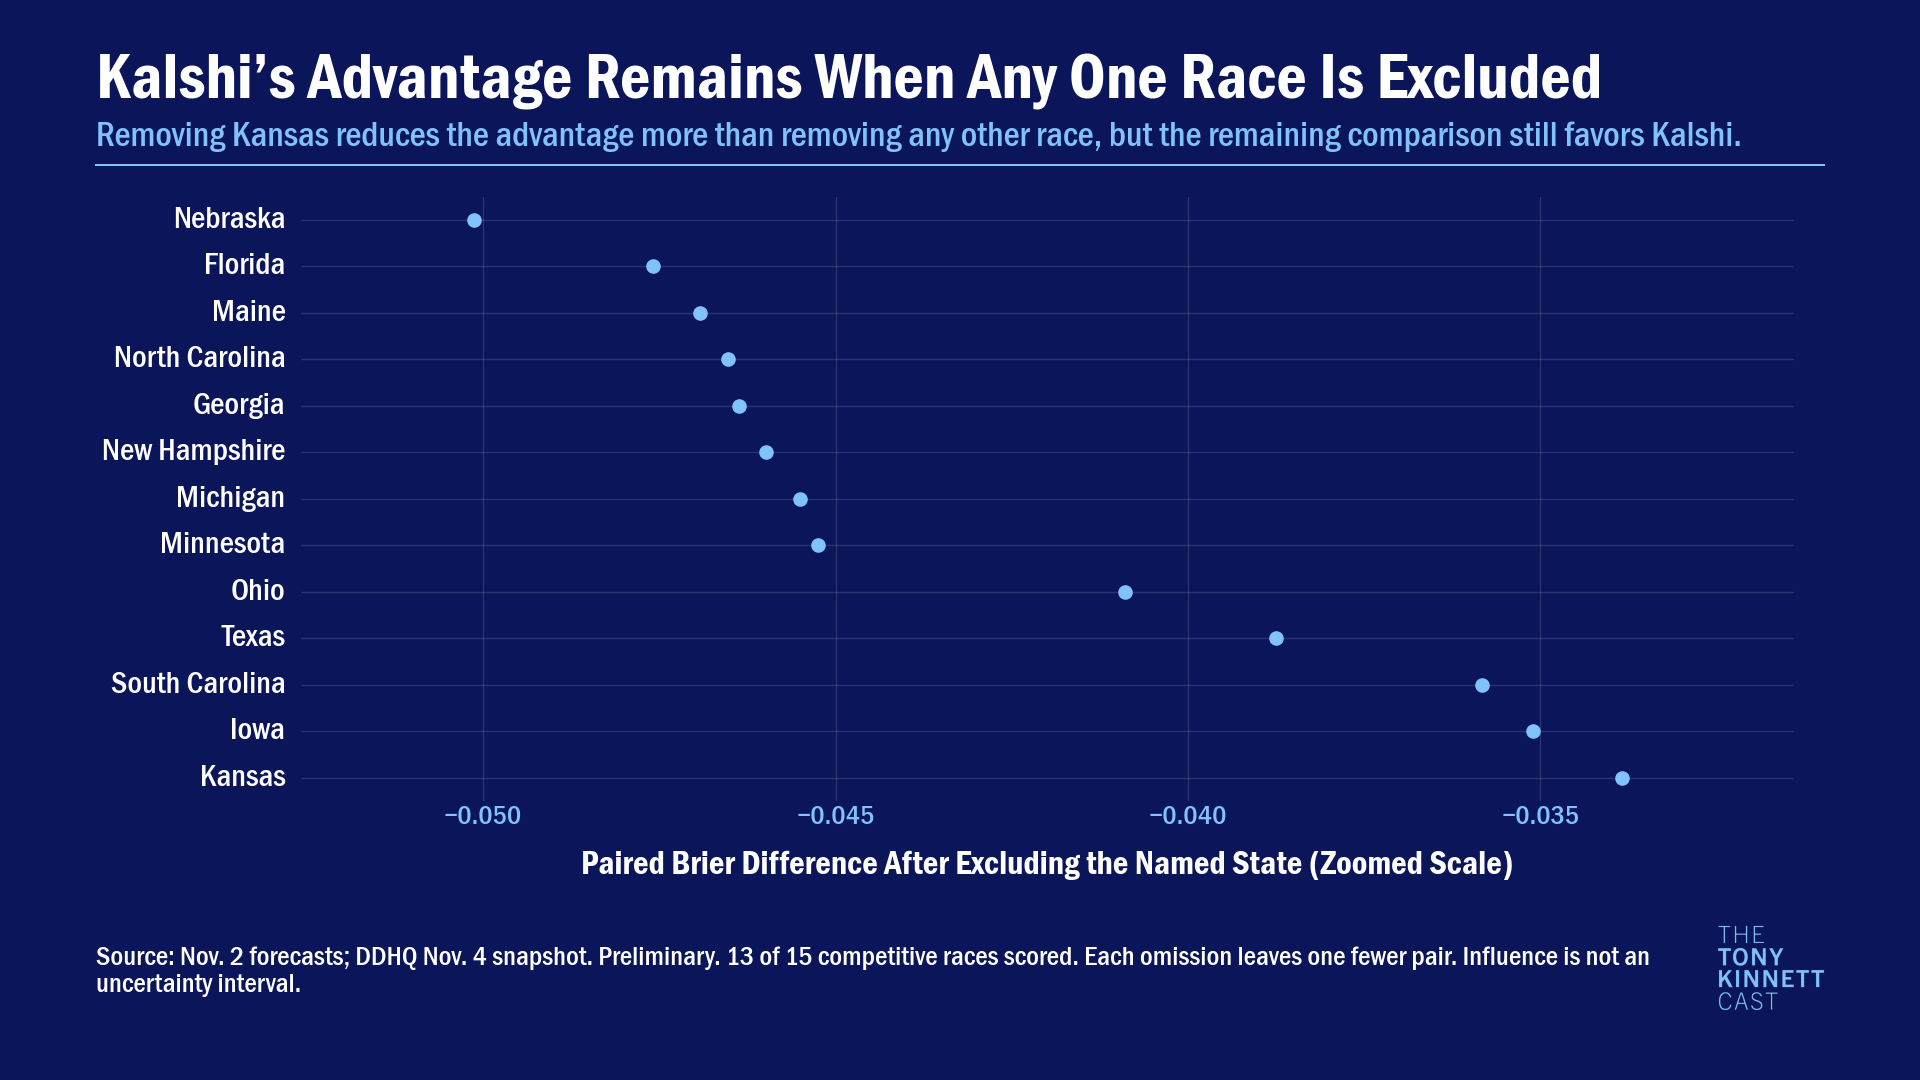

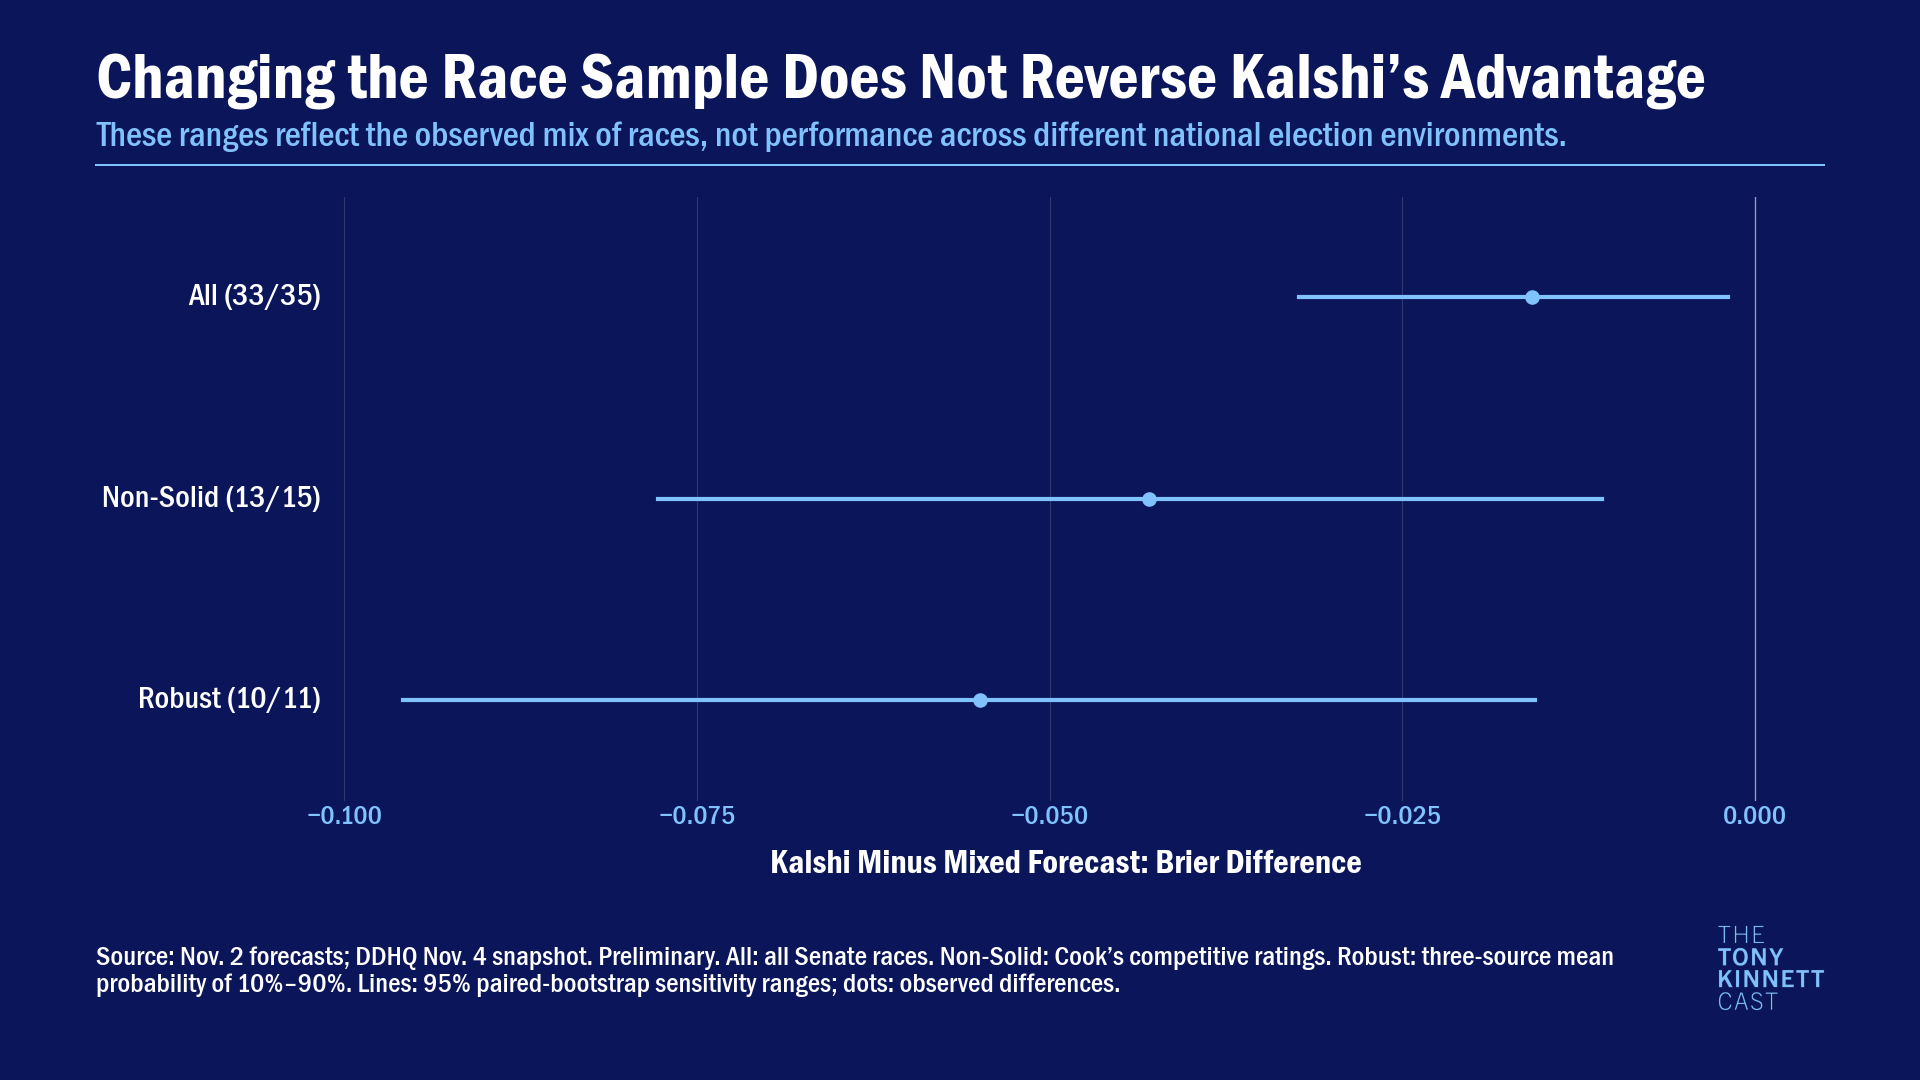

In [5]:
paired_records, paired_races, influence_records = [], [], []
primary_bootstrap = {}
for sample in SAMPLES:
    frame = select_sample(full_frame, sample)
    for first, second in combinations(SOURCES, 2):
        for metric in ("brier", "log"):
            summary, rows, leave_out, draws = paired_analysis(frame, first, second, metric=metric)
            paired_records.append({"sample": sample, **summary})
            if len(rows):
                detail = rows[["loss_first", "loss_second", "difference", "_weight"]].copy()
                detail["contribution"] = detail.difference * detail._weight
                paired_races.append(detail.reset_index().assign(sample=sample, first=first, second=second, metric=metric))
            if len(leave_out):
                influence_records.append(leave_out.assign(sample=sample, first=first, second=second, metric=metric))
            if first == "p_kalshi" and second == "p_model_mean" and metric == "brier":
                primary_bootstrap[sample] = draws
pairs = table("paired-comparisons", pd.DataFrame(paired_records))
per_race_pairs = table("paired-race-contributions", pd.concat(paired_races, ignore_index=True) if paired_races else pd.DataFrame(), show=False)
influences = table("leave-one-out", pd.concat(influence_records, ignore_index=True) if influence_records else pd.DataFrame(), show=False)
flip = exact_sign_flip(primary.per_race.difference.to_numpy() if primary.n_eligible else [])
table("primary-sign-flip", pd.DataFrame([flip]))
for sample, draws in primary_bootstrap.items():
    table("bootstrap-primary-" + sample, pd.DataFrame({"replicate": np.arange(len(draws)), "difference": draws}), show=False)

if primary.n_eligible:
    primary_detail = primary.per_race[["loss_first", "loss_second", "difference", "_weight"]].copy()
    primary_detail["contribution"] = primary_detail.difference * primary_detail._weight
    table("primary-race-losses", primary_detail.reset_index())
    d = primary.per_race.reset_index()
    d["state"] = d.race_id.str[:2].map(STATE_NAMES)
    better = int(d.difference.lt(0).sum())
    title = f"Kalshi Scored Better in {better} of {primary.n_eligible} Competitive Senate Races"
    assert better == sum(primary.per_race.loss_first < primary.per_race.loss_second)
    difference_bars("01-primary-race-differences", title, d,
              label="state", value="difference", xlabel="Brier Loss: Kalshi Minus Mixed Forecast",
              subtitle="Each bar compares errors in one resolved race. Left favors Kalshi; right favors the mixed forecast.",
              note=coverage_note)
if len(influences):
    d = influences.query("sample == 'non_solid' and first == 'p_kalshi' and second == 'p_model_mean' and metric == 'brier'").copy()
    if len(d):
        d["state"] = d.race_id.str[:2].map(STATE_NAMES)
        largest = d.loc[d.change_from_full.abs().idxmax()]
        all_favor = bool(d.leave_one_out.lt(0).all())
        title = ("Kalshi’s Advantage Remains When Any One Race Is Excluded" if all_favor else
                 "Excluding Individual Races Changes the Forecast Comparison")
        subtitle = ("Removing Kansas reduces the advantage more than removing any other race, but the remaining comparison still favors Kalshi."
                    if all_favor and largest.race_id == "KS-SEN" and largest.change_from_full > 0 else
                    "Each estimate removes one eligible race from both forecasts; the resulting differences show sensitivity to individual races.")
        d = d.sort_values(["leave_one_out", "state"], kind="stable")
        dot_chart("02-primary-influence", title, d, zero_reference=False, row_guides=True,
                  label="state", value="leave_one_out", xlabel="Paired Brier Difference After Excluding the Named State",
                  subtitle=subtitle, note=coverage_note + "Each omission leaves one fewer pair. Influence is not an uncertainty interval.")
d = pairs.query("first == 'p_kalshi' and second == 'p_model_mean' and metric == 'brier' and n_eligible > 0").copy()
if len(d):
    d["label"] = d.apply(lambda r: f"{SAMPLE_NAMES[r['sample']]} ({r.n_eligible}/{r.n_planned})", axis=1)
    title = ("Changing the Race Sample Does Not Reverse Kalshi’s Advantage" if d.value.lt(0).all() else
             "The Forecast Comparison Depends on the Race Sample")
    dot_chart("03-bootstrap-sensitivity", title, d, label="label", value="value", low="low", high="high",
              xlabel="Kalshi Minus Mixed Forecast: Brier Difference",
              subtitle="These ranges reflect the observed mix of races, not performance across different national election environments.",
              note="All: all Senate races. Non-Solid: Cook’s competitive ratings. Robust: three-source mean probability of 10%–90%. Lines: 95% paired-bootstrap sensitivity ranges; dots: observed differences.")


## 3. Calibration diagnostics

For each source and subset, outcomes are simulated from that source's own probabilities: 20,000 draws, seed 20261105. The Gaussian copula uses `zᵢ = √ρ S + √(1−ρ) εᵢ`, then `yᵢ = 1[zᵢ ≤ Φ⁻¹(pᵢ)]`. Each marginal is pᵢ in the model; finite simulation frequencies fluctuate. Common latent draws keep scenario comparisons reproducible.

The grid 0, 0.1, 0.25, 0.5 describes **latent normal correlation**, not binary outcome correlation or an estimated dependence level. Observed percentiles use midranks; ranges describe simulated outcomes rather than confidence in forecast superiority. Low observed loss can reflect luck or cautious forecasts.

Spiegelhalter's Z is `Σ(y−p)(1−2p) / √Σ[(1−2p)²p(1−p)]`, using independent Bernoulli outcomes; zero variance gives unavailable Z. See the [methods reference](https://www.stata.com/manuals/rbrier.pdf). Reported Z is an independence-only diagnostic, not a dependence-adjusted test. Small samples and a shared national environment limit all calibration conclusions.

,source,rho_latent,n_planned,n_eligible,observed_brier,expected_brier,simulated_mean,sd,low,high,observed_percentile,spiegelhalter_z_independent,status,sample,snapshot,synthetic
0,p_kalshi,0.00,35,33,0.038438,0.077350,0.077605,0.028909,0.028135,0.142200,6.7750,-1.357368,qualified,all,ddhq-20261104-222052-est,False
1,p_kalshi,0.10,35,33,0.038438,0.077350,0.077603,0.029025,0.028135,0.143044,6.8500,-1.357368,qualified,all,ddhq-20261104-222052-est,False
2,p_kalshi,0.25,35,33,0.038438,0.077350,0.077718,0.032602,0.028135,0.154135,8.0450,-1.357368,qualified,all,ddhq-20261104-222052-est,False
3,p_kalshi,0.50,35,33,0.038438,0.077350,0.077419,0.043052,0.028135,0.200256,12.1550,-1.357368,qualified,all,ddhq-20261104-222052-est,False
4,p_economist,0.00,35,33,0.064085,0.069248,0.069356,0.025720,0.031358,0.128327,46.9275,-0.200874,qualified,all,ddhq-20261104-222052-est,False
5,p_economist,0.10,35,33,0.064085,0.069248,0.069269,0.025906,0.031358,0.128933,46.9125,-0.200874,qualified,all,ddhq-20261104-222052-est,False
6,p_economist,0.25,35,33,0.064085,0.069248,0.069385,0.028751,0.031358,0.139842,48.4700,-0.200874,qualified,all,ddhq-20261104-222052-est,False
7,p_economist,0.50,35,33,0.064085,0.069248,0.069427,0.037427,0.030145,0.170145,53.7000,-0.200874,qualified,all,ddhq-20261104-222052-est,False
8,p_votehub,0.00,35,33,0.046542,0.070427,0.070484,0.025562,0.030482,0.128180,21.1150,-0.938721,qualified,all,ddhq-20261104-222052-est,False
9,p_votehub,0.10,35,33,0.046542,0.070427,0.070467,0.025795,0.030482,0.129270,20.7950,-0.938721,qualified,all,ddhq-20261104-222052-est,False


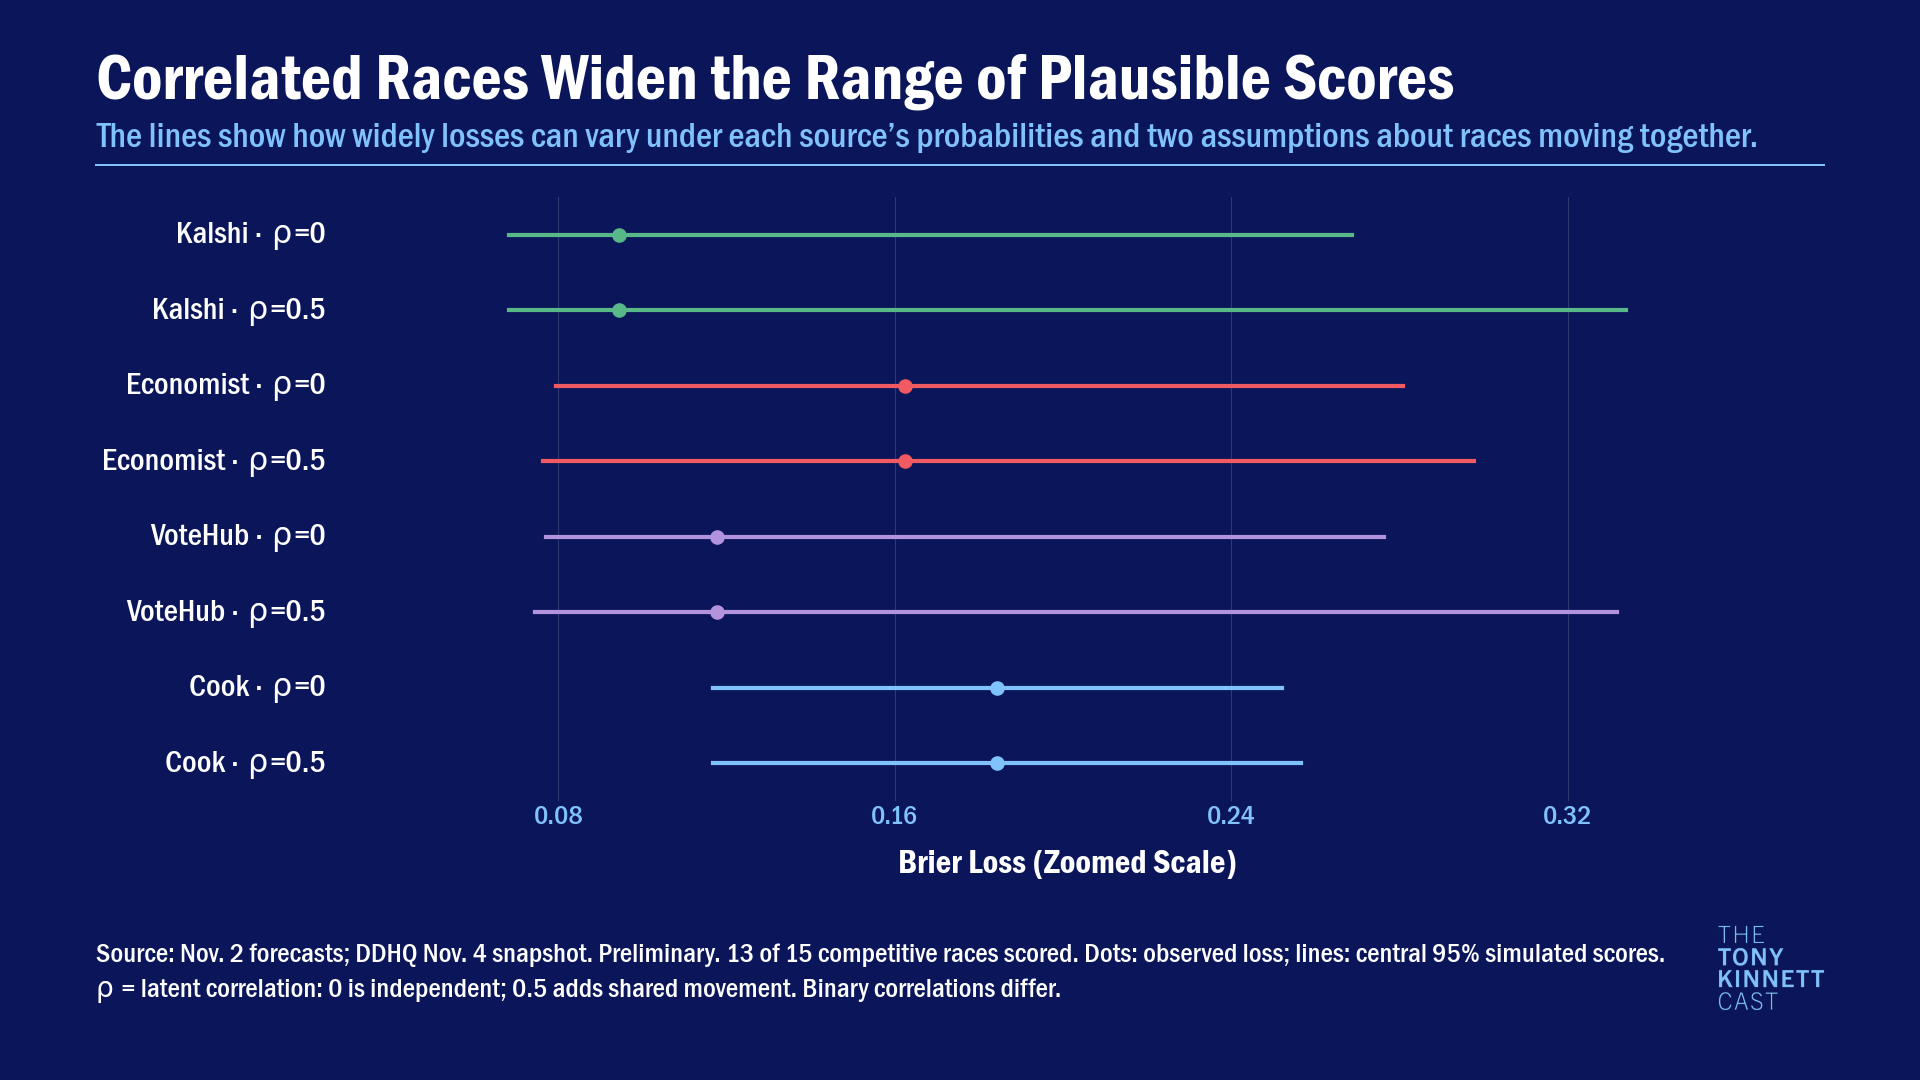

In [6]:
calibration_records = []
for sample in SAMPLES:
    for source in SOURCES:
        calibration_records.append(calibration(select_sample(full_frame, sample), source, shared_latent, residual_latent).assign(sample=sample))
calibrations = table("calibration", pd.concat(calibration_records, ignore_index=True))

if primary.n_eligible:
    d = calibrations.query("sample == 'non_solid' and rho_latent in [0, .5] and source in ['p_kalshi','p_economist','p_votehub','p_cook_primary']").copy()
    d["label"] = d.apply(lambda r: f"{SOURCES[r.source]} · ρ={r.rho_latent:g}", axis=1)
    d["ink"] = d.source.map({"p_kalshi": colors["kalshi"], "p_economist": colors["economist"],
                            "p_votehub": colors["votehub"], "p_cook_primary": colors["cook"]})
    widths = d.assign(width=d.high - d.low).pivot(index="source", columns="rho_latent", values="width")
    title = ("Correlated Races Widen the Range of Plausible Scores" if widths[.5].ge(widths[0]).all() else
             "Dependence Changes the Range of Plausible Scores")
    dot_chart("04-calibration", title, d, zero_reference=False,
              label="label", value="observed_brier", low="low", high="high", color="ink", xlabel="Brier Loss",
              subtitle="The lines show how widely losses can vary under each source’s probabilities and two assumptions about races moving together.",
              note=coverage_note + "Dots: observed loss; lines: central 95% simulated scores. ρ = latent correlation: 0 is independent; 0.5 adds shared movement. Binary correlations differ.")


## 4. Vote-share accuracy

Shares are converted to A/(A+B) and scored only when completeness and source-specific target compatibility are documented. A call alone never qualifies vote shares. Signed bias is forecast minus actual in percentage points; each race's error equals the evaluated sample's bias plus its deviation. This algebraic decomposition does not estimate an independent national error or remove correlation. RCP versus Silver uses only their common eligible races; Silver is the recorded weighted polling average.

In [7]:
share_records, share_details = [], []
for source in ("economist", "votehub", "rcp", "silver"):
    for comparison, peers in [("source coverage", ())] + ([("common polls", ("share_silver" if source == "rcp" else "share_rcp",))] if source in ("rcp", "silver") else []):
        for metric in ("mae", "rmse", "bias"):
            r = vote_share_score(full_frame, "share_" + source, peers=peers, metric=metric)
            share_records.append({"source": source, "comparison": comparison, "metric": metric,
                                  "percentage_points": None if r.value is None else 100 * r.value, **r.summary()})
            if metric == "bias" and r.n_eligible:
                detail = r.per_race[["error", "centered_error"]].copy() * 100
                detail["bias"] = r.value * 100
                np.testing.assert_allclose(detail.error, detail.bias + detail.centered_error)
                share_details.append(detail.reset_index().assign(source=source, comparison=comparison))
shares = table("vote-share-errors", pd.DataFrame(share_records))
share_decomposition = table("vote-share-decomposition", pd.concat(share_details, ignore_index=True) if share_details else pd.DataFrame(), show=bool(share_details))
if not shares.n_eligible.any():
    display(Markdown("**Chart #5 is gated: 0 eligible comparable results.** Both real snapshots lack documented complete, comparable results; ranked-choice targets/rounds are unresolved, including AK and ME. Source-specific completeness and forecast-target compatibility evidence must be supplied in a new validated snapshot. Reporting percentages and vote leads cannot substitute. No vote-share graphic is exported."))
else:
    d = shares.query("metric == 'mae' and comparison == 'source coverage' and n_eligible > 0").copy()
    d["label"] = d.apply(lambda r: f"{dict(economist='Economist', votehub='VoteHub', rcp='RCP', silver='Silver Bulletin')[r.source]} ({r.n_eligible})", axis=1)
    dot_chart("05-vote-share-errors", "Comparable Vote-Share Errors Use Separate Eligibility", d, label="label", value="percentage_points", xlabel="Mean Absolute Error (Percentage Points)",
              subtitle="Only complete results with documented forecast-target compatibility are eligible.",
              note="Eligible counts are shown by source. Poll comparisons use common races. Synthetic fixtures are not election findings.")
    common = shares.query("comparison == 'common polls' and metric == 'mae'").set_index("source")
    if common.n_eligible.gt(0).all():
        difference = common.loc["silver", "percentage_points"] - common.loc["rcp", "percentage_points"]
        display(Markdown(f"On {int(common.loc['silver', 'n_eligible'])} common races, Silver minus RCP MAE is {difference:+.4f} percentage points; negative indicates smaller Silver error. Descriptive only."))

,source,comparison,metric,percentage_points,value,status,n_planned,n_eligible,snapshot,synthetic
0,economist,source coverage,mae,None,None,unavailable,35,0,ddhq-20261104-222052-est,False
1,economist,source coverage,rmse,None,None,unavailable,35,0,ddhq-20261104-222052-est,False
2,economist,source coverage,bias,None,None,unavailable,35,0,ddhq-20261104-222052-est,False
3,votehub,source coverage,mae,None,None,unavailable,35,0,ddhq-20261104-222052-est,False
4,votehub,source coverage,rmse,None,None,unavailable,35,0,ddhq-20261104-222052-est,False
5,votehub,source coverage,bias,None,None,unavailable,35,0,ddhq-20261104-222052-est,False
6,rcp,source coverage,mae,None,None,unavailable,35,0,ddhq-20261104-222052-est,False
7,rcp,source coverage,rmse,None,None,unavailable,35,0,ddhq-20261104-222052-est,False
8,rcp,source coverage,bias,None,None,unavailable,35,0,ddhq-20261104-222052-est,False
9,rcp,common polls,mae,None,None,unavailable,35,0,ddhq-20261104-222052-est,False


**Chart #5 is gated: 0 eligible comparable results.** Both real snapshots lack documented complete, comparable results; ranked-choice targets/rounds are unresolved, including AK and ME. Source-specific completeness and forecast-target compatibility evidence must be supplied in a new validated snapshot. Reporting percentages and vote leads cannot substitute. No vote-share graphic is exported.

## 5. Does the market add information? Descriptive comparisons

The primary contrast is repeated here for context. Economist alone is the cleaner market-free comparison: its published inputs list polling and fundamentals without market prices. VoteHub Complete already uses Kalshi and expert ratings. The fixed blend is 0.5 Kalshi + 0.5 mixed mean; it adds market exposure, not a new information source. No weight is fitted to these outcomes. A lower realized loss supports no general claim that markets add information.

,sample,value,status,n_planned,n_eligible,first,second,metric,low,high,n_nonzero,snapshot,synthetic
0,all,-0.025647,qualified,35,33,p_kalshi,p_economist,brier,-0.050712,-0.003839,30,ddhq-20261104-222052-est,False
2,all,-0.008105,qualified,35,33,p_kalshi,p_votehub,brier,-0.018716,-0.000286,30,ddhq-20261104-222052-est,False
6,all,-0.015834,qualified,35,33,p_kalshi,p_model_mean,brier,-0.032313,-0.001922,30,ddhq-20261104-222052-est,False
8,all,-0.006992,qualified,35,33,p_kalshi,p_blend,brier,-0.014715,-0.000391,30,ddhq-20261104-222052-est,False
30,non_solid,-0.067921,qualified,15,13,p_kalshi,p_economist,brier,-0.121850,-0.017152,13,ddhq-20261104-222052-est,False
32,non_solid,-0.023257,qualified,15,13,p_kalshi,p_votehub,brier,-0.046158,-0.005123,13,ddhq-20261104-222052-est,False
36,non_solid,-0.042977,qualified,15,13,p_kalshi,p_model_mean,brier,-0.077735,-0.010856,13,ddhq-20261104-222052-est,False
38,non_solid,-0.019546,qualified,15,13,p_kalshi,p_blend,brier,-0.036025,-0.004295,13,ddhq-20261104-222052-est,False
60,robust,-0.086832,qualified,11,10,p_kalshi,p_economist,brier,-0.149883,-0.024694,10,ddhq-20261104-222052-est,False
62,robust,-0.029657,qualified,11,10,p_kalshi,p_votehub,brier,-0.057897,-0.007201,10,ddhq-20261104-222052-est,False


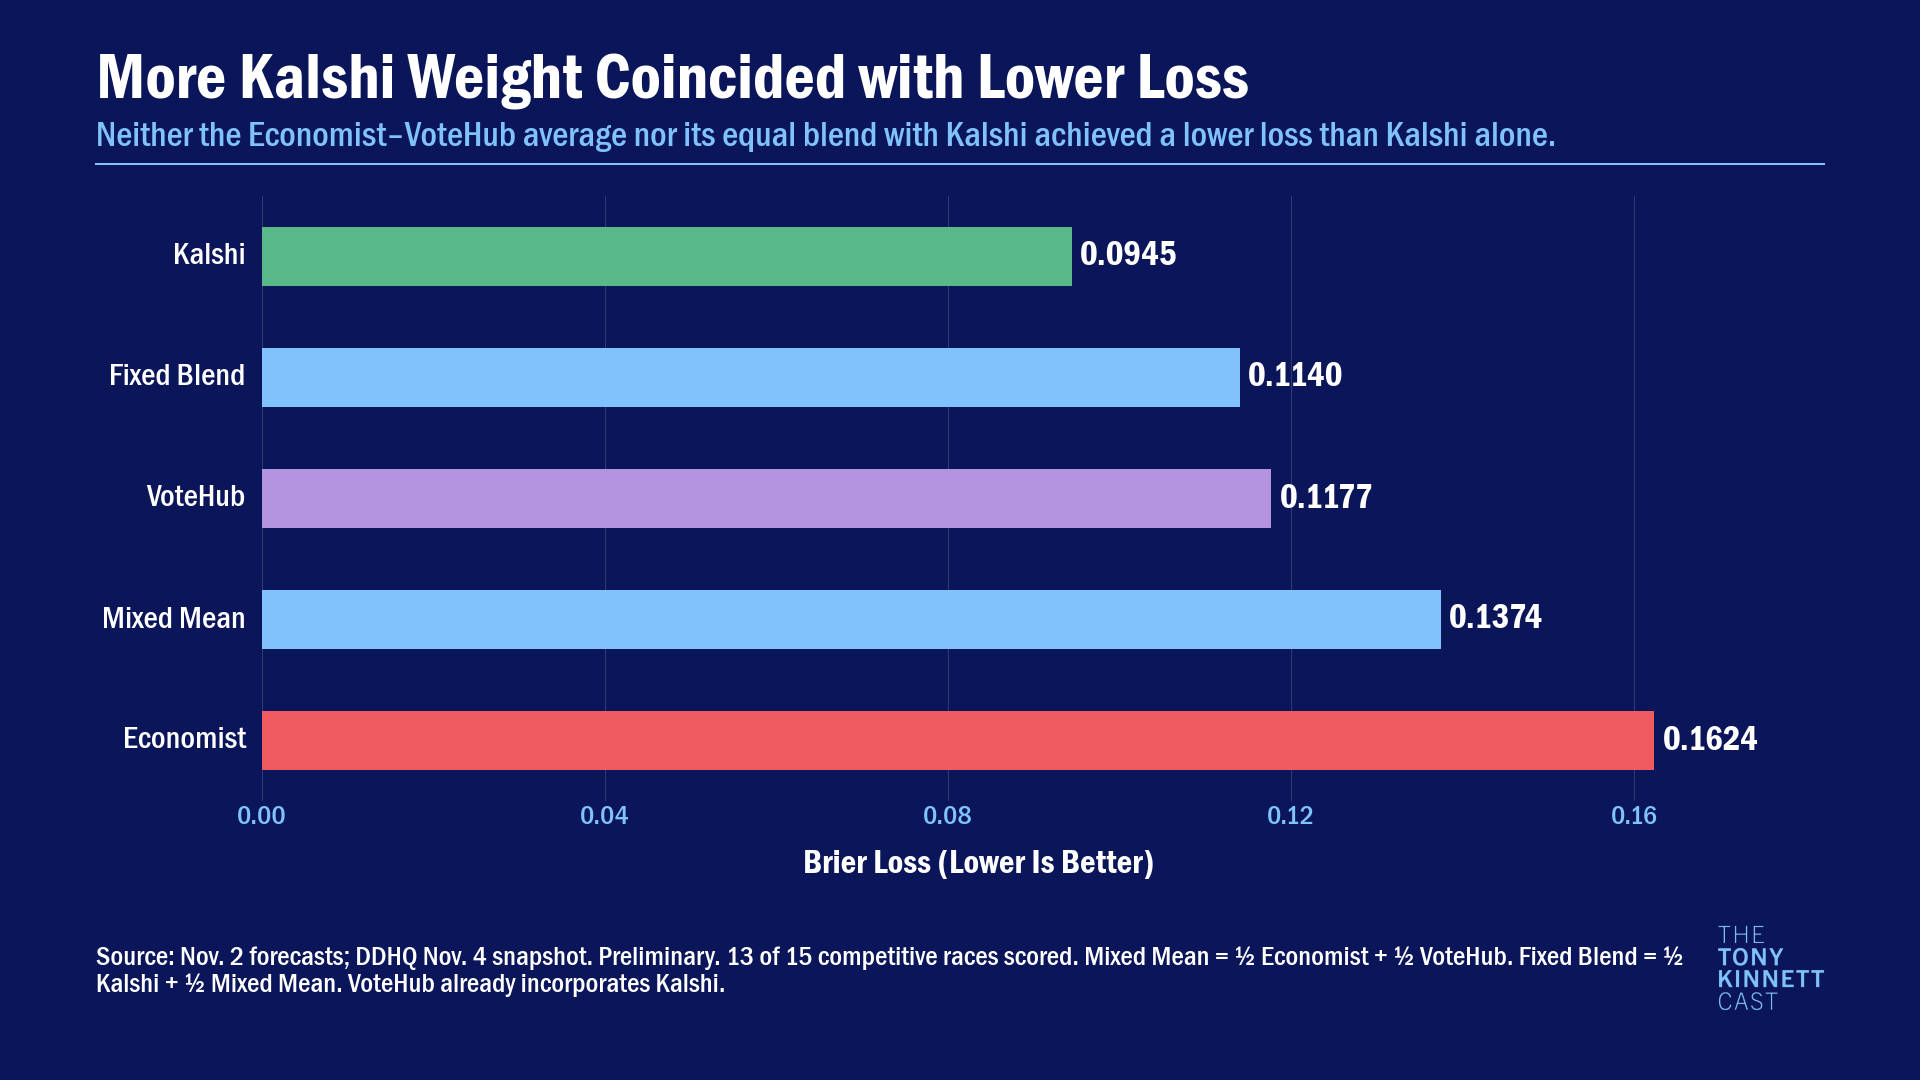

In [8]:

fixed = pairs.query("first == 'p_kalshi' and second in ['p_model_mean','p_economist','p_votehub','p_blend'] and metric == 'brier'").copy()
table("fixed-comparisons", fixed)
if primary.n_eligible:
    d = scores.query("sample == 'non_solid' and metric == 'brier' and source in ['Kalshi','Economist','VoteHub','Mixed Mean','Fixed Blend']").copy()
    d = d.sort_values("value", kind="stable")
    d["label"] = d.source
    d["ink"] = d.source.map({"Kalshi": colors["kalshi"], "Economist": colors["economist"],
                            "VoteHub": colors["votehub"], "Mixed Mean": colors["model_mean"], "Fixed Blend": colors["blend"]})
    losses = d.set_index("source").value
    follows = losses["Kalshi"] < losses["Fixed Blend"] < losses["Mixed Mean"]
    title = ("More Kalshi Weight Coincided with Lower Loss" if follows else
             "Fixed Forecast Combinations Have Different Realized Losses")
    subtitle = ("Neither the Economist–VoteHub average nor its equal blend with Kalshi achieved a lower loss than Kalshi alone."
                if losses["Kalshi"] <= min(losses["Mixed Mean"], losses["Fixed Blend"]) else
                "The same resolved races compare Kalshi, the mixed forecast, and their fixed equal blend.")
    bar_chart("06-fixed-combinations", title, subtitle, d, label="label", value="value", color="ink",
              note=coverage_note + "Mixed Mean = ½ Economist + ½ VoteHub. Fixed Blend = ½ Kalshi + ½ Mixed Mean. VoteHub already incorporates Kalshi.")


## 6. Favorite–longshot pattern — exploratory

Each eligible race contributes one less-favored event derived from raw Candidate A probability: A if pA<0.5, otherwise its binary complement. Complement probabilities are not the separately recorded B contract prices; raw versus normalized scoring remains separate. Exactly 0.5 is a tie and has no longshot. Fixed bins were selected for description, not fitted to results. Compare expected wins with observed wins; sparse bins and correlated outcomes cannot establish systematic longshot overpricing. Volume analysis belongs to the next notebook.

,band,n,expected_wins,observed_wins,observed_minus_expected,status,snapshot,synthetic
0,0–<5%,18,0.327,0.0,-0.327,exploratory,ddhq-20261104-222052-est,False
1,5–<10%,5,0.334,0.0,-0.334,exploratory,ddhq-20261104-222052-est,False
2,10–<25%,4,0.750,0.0,-0.750,exploratory,ddhq-20261104-222052-est,False
3,25–<50%,5,1.570,1.0,-0.570,exploratory,ddhq-20261104-222052-est,False


Eligible tied forecasts excluded from longshot bins: 1


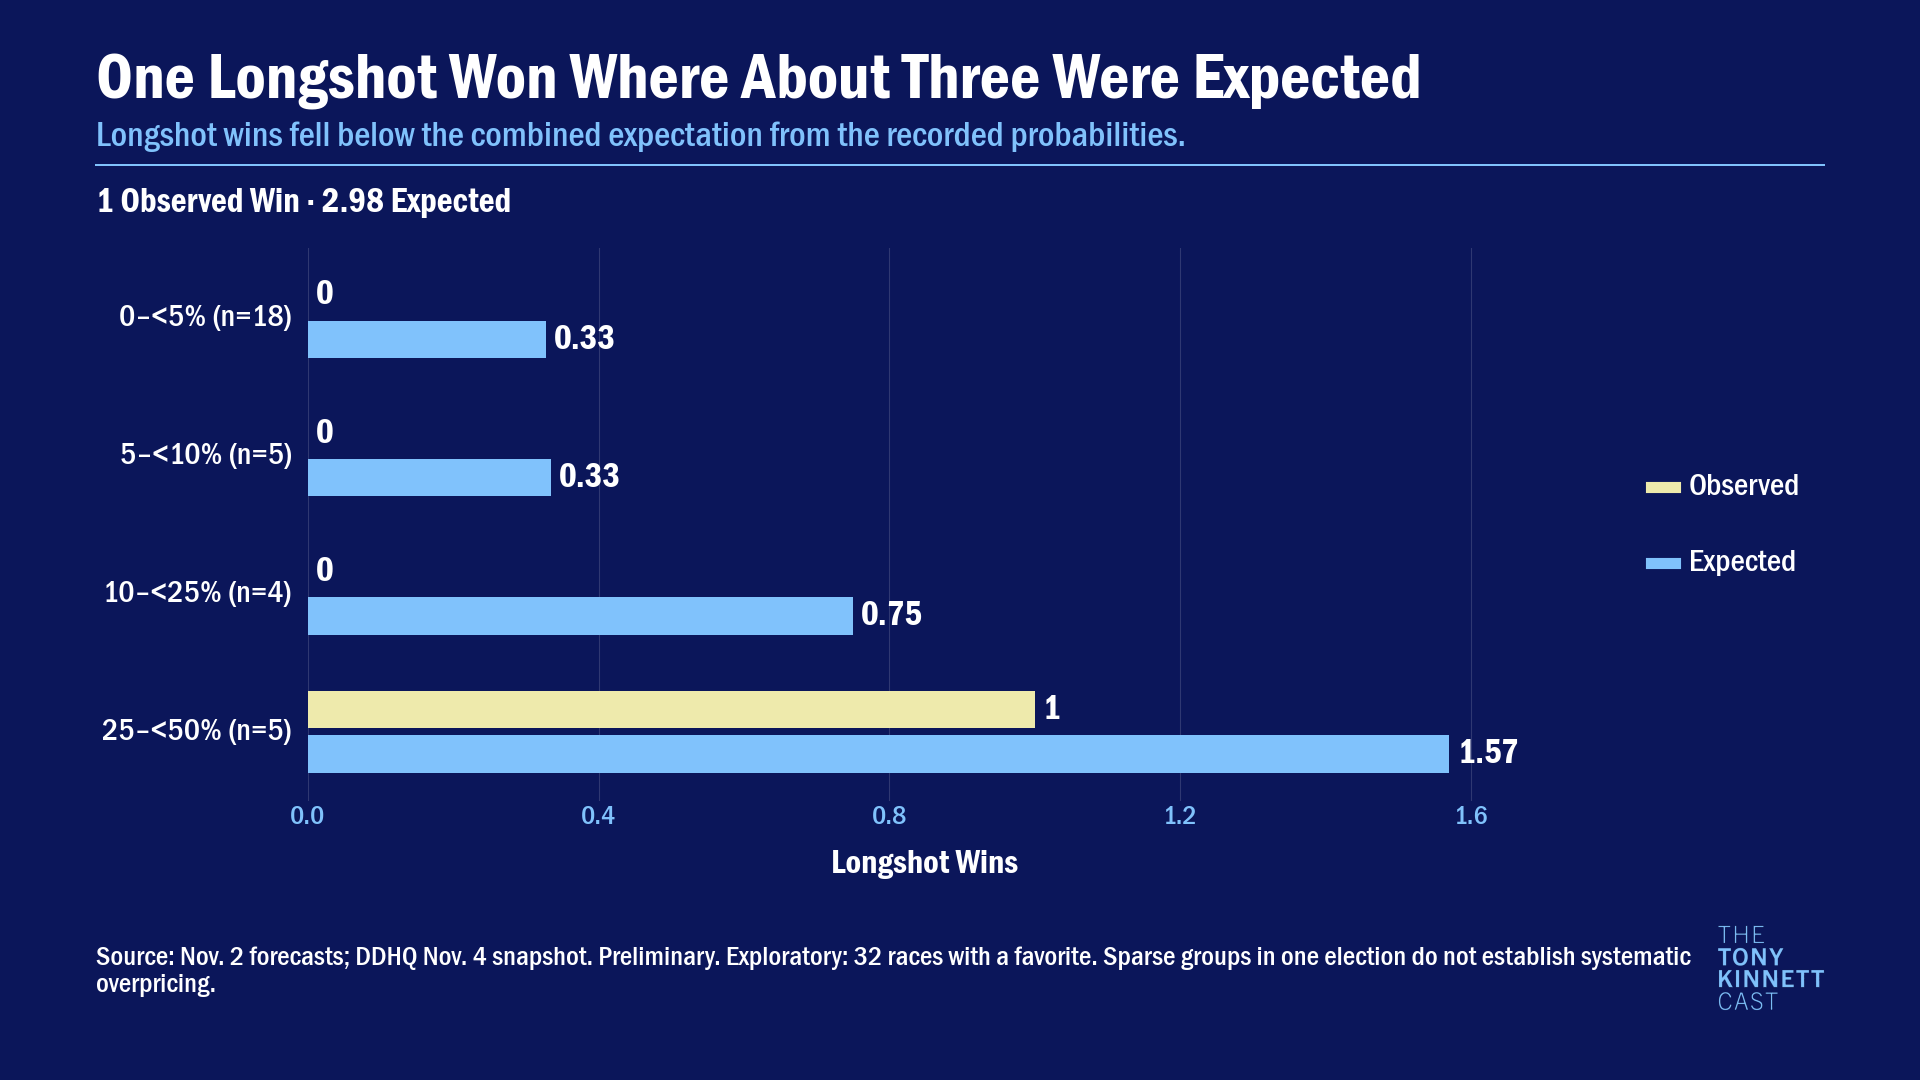

In [9]:
longshots = longshot_rows(full_frame)
table("longshot-races", longshots.reset_index(), show=False)
longshot_summary = []
for band in ["0–<5%", "5–<10%", "10–<25%", "25–<50%"]:
    r = longshots.loc[longshots.band == band]
    longshot_summary.append({"band": band, "n": len(r), "expected_wins": r.longshot_probability.sum(),
                             "observed_wins": r.longshot_won.sum() if len(r) else None,
                             "observed_minus_expected": (r.longshot_won - r.longshot_probability).sum() if len(r) else None,
                             "status": "exploratory" if len(r) else "unavailable"})
longshot_summary = table("longshot-bands", pd.DataFrame(longshot_summary))
print("Eligible tied forecasts excluded from longshot bins:", int(longshots.tie.sum()))

longshot_chart(longshot_summary)


## 7. Cook mapping sensitivity

Repeat every Cook-dependent score, skill reference, paired comparison, leave-one-out influence, bootstrap sensitivity, and calibration diagnostic using the primary, Senate-only, and wide mappings. Toss-Ups remain 0.5. Ties use minimum rank, so tied first places are both rank 1. No mapping is selected by realized fit. Non-Cook probability losses, the primary contrast, and the fixed combinations do not depend on the Cook mapping; the frozen non-Solid membership does not change.

,sample,mapping,metric,clipped,value,status,n_planned,n_eligible,snapshot,synthetic
0,all,primary,brier,False,0.072700,qualified,35,33,ddhq-20261104-222052-est,False
1,all,primary,log,True,0.225767,qualified,35,33,ddhq-20261104-222052-est,False
2,all,primary,log,False,0.225767,qualified,35,33,ddhq-20261104-222052-est,False
3,all,senate,brier,False,0.074754,qualified,35,33,ddhq-20261104-222052-est,False
4,all,senate,log,True,0.255985,qualified,35,33,ddhq-20261104-222052-est,False
5,all,senate,log,False,0.255985,qualified,35,33,ddhq-20261104-222052-est,False
6,all,wide,brier,False,0.069455,qualified,35,33,ddhq-20261104-222052-est,False
7,all,wide,log,True,0.210605,qualified,35,33,ddhq-20261104-222052-est,False
8,all,wide,log,False,0.210605,qualified,35,33,ddhq-20261104-222052-est,False
9,non_solid,primary,brier,False,0.184392,qualified,15,13,ddhq-20261104-222052-est,False


,sample,mapping,source,reference,value,status,n_planned,n_eligible,snapshot,synthetic
0,all,primary,p_kalshi,p_cook_primary,0.471285,qualified,35,33,ddhq-20261104-222052-est,False
1,all,primary,p_kalshi,p_constant,0.485941,qualified,35,33,ddhq-20261104-222052-est,False
2,all,primary,p_kalshi,p_uniform,0.846250,qualified,35,33,ddhq-20261104-222052-est,False
3,all,primary,p_economist,p_cook_primary,0.118503,qualified,35,33,ddhq-20261104-222052-est,False
4,all,primary,p_economist,p_constant,0.142938,qualified,35,33,ddhq-20261104-222052-est,False
5,all,primary,p_economist,p_uniform,0.743661,qualified,35,33,ddhq-20261104-222052-est,False
6,all,primary,p_votehub,p_cook_primary,0.359804,qualified,35,33,ddhq-20261104-222052-est,False
7,all,primary,p_votehub,p_constant,0.377551,qualified,35,33,ddhq-20261104-222052-est,False
8,all,primary,p_votehub,p_uniform,0.813831,qualified,35,33,ddhq-20261104-222052-est,False
9,all,primary,p_model_mean,p_cook_primary,0.253483,qualified,35,33,ddhq-20261104-222052-est,False


,sample,mapping,value,status,n_planned,n_eligible,first,second,metric,low,high,n_nonzero,snapshot,synthetic
0,all,primary,-0.034262,qualified,35,33,p_kalshi,p_cook_primary,brier,-0.070102,-0.005043,28,ddhq-20261104-222052-est,False
1,all,primary,-0.079810,qualified,35,33,p_kalshi,p_cook_primary,log,-0.205855,0.010787,26,ddhq-20261104-222052-est,False
2,all,primary,-0.008615,qualified,35,33,p_economist,p_cook_primary,brier,-0.035533,0.017602,24,ddhq-20261104-222052-est,False
3,all,primary,-0.030948,qualified,35,33,p_economist,p_cook_primary,log,-0.129107,0.044865,24,ddhq-20261104-222052-est,False
4,all,primary,-0.026158,qualified,35,33,p_votehub,p_cook_primary,brier,-0.057041,-0.000889,24,ddhq-20261104-222052-est,False
5,all,primary,-0.069496,qualified,35,33,p_votehub,p_cook_primary,log,-0.181463,0.010101,24,ddhq-20261104-222052-est,False
6,all,primary,-0.018428,qualified,35,33,p_model_mean,p_cook_primary,brier,-0.046097,0.005357,24,ddhq-20261104-222052-est,False
7,all,primary,-0.052184,qualified,35,33,p_model_mean,p_cook_primary,log,-0.155664,0.021998,24,ddhq-20261104-222052-est,False
8,all,primary,-0.027270,qualified,35,33,p_blend,p_cook_primary,brier,-0.058643,-0.001760,30,ddhq-20261104-222052-est,False
9,all,primary,-0.067499,qualified,35,33,p_blend,p_cook_primary,log,-0.182050,0.012784,28,ddhq-20261104-222052-est,False


,sample,mapping,first,metric,n_omissions,minimum,maximum,max_absolute_change,snapshot,synthetic
0,all,primary,p_blend,brier,33,-0.030153,-0.016485,0.010785,ddhq-20261104-222052-est,False
1,all,primary,p_blend,log,33,-0.077020,-0.020916,0.046583,ddhq-20261104-222052-est,False
2,all,primary,p_economist,brier,33,-0.016825,-0.000775,0.008210,ddhq-20261104-222052-est,False
3,all,primary,p_economist,log,33,-0.048938,0.007233,0.038182,ddhq-20261104-222052-est,False
4,all,primary,p_kalshi,brier,33,-0.038033,-0.021749,0.012514,ddhq-20261104-222052-est,False
5,all,primary,p_kalshi,log,33,-0.091517,-0.029031,0.050779,ddhq-20261104-222052-est,False
6,all,primary,p_model_mean,brier,33,-0.023301,-0.009442,0.008987,ddhq-20261104-222052-est,False
7,all,primary,p_model_mean,log,33,-0.062597,-0.010493,0.041691,ddhq-20261104-222052-est,False
8,all,primary,p_votehub,brier,33,-0.029564,-0.016016,0.010142,ddhq-20261104-222052-est,False
9,all,primary,p_votehub,log,33,-0.080613,-0.024665,0.044831,ddhq-20261104-222052-est,False


,source,rho_latent,n_planned,n_eligible,observed_brier,expected_brier,simulated_mean,sd,low,high,observed_percentile,spiegelhalter_z_independent,status,sample,mapping,snapshot,synthetic
0,p_cook_primary,0.00,35,33,0.072700,0.060936,0.061010,0.020259,0.046033,0.105427,58.2500,0.583907,qualified,all,primary,ddhq-20261104-222052-est,False
1,p_cook_primary,0.10,35,33,0.072700,0.060936,0.060994,0.020550,0.046033,0.105427,58.6250,0.583907,qualified,all,primary,ddhq-20261104-222052-est,False
2,p_cook_primary,0.25,35,33,0.072700,0.060936,0.061065,0.022962,0.046033,0.129064,61.3750,0.583907,qualified,all,primary,ddhq-20261104-222052-est,False
3,p_cook_primary,0.50,35,33,0.072700,0.060936,0.061110,0.030817,0.046033,0.157548,68.7800,0.583907,qualified,all,primary,ddhq-20261104-222052-est,False
4,p_cook_senate,0.00,35,33,0.074754,0.055670,0.055776,0.017200,0.045603,0.104451,75.4000,1.116559,qualified,all,senate,ddhq-20261104-222052-est,False
5,p_cook_senate,0.10,35,33,0.074754,0.055670,0.055690,0.017403,0.045603,0.104451,75.7950,1.116559,qualified,all,senate,ddhq-20261104-222052-est,False
6,p_cook_senate,0.25,35,33,0.074754,0.055670,0.055854,0.019699,0.045603,0.104997,77.4550,1.116559,qualified,all,senate,ddhq-20261104-222052-est,False
7,p_cook_senate,0.50,35,33,0.074754,0.055670,0.055817,0.026740,0.045603,0.134148,82.6350,1.116559,qualified,all,senate,ddhq-20261104-222052-est,False
8,p_cook_wide,0.00,35,33,0.069455,0.085091,0.085231,0.021486,0.057333,0.135515,14.1900,-0.731669,qualified,all,wide,ddhq-20261104-222052-est,False
9,p_cook_wide,0.10,35,33,0.069455,0.085091,0.085229,0.021477,0.057333,0.135515,13.7550,-0.731669,qualified,all,wide,ddhq-20261104-222052-est,False


,sample,mapping,source,rank,rank_change,snapshot,synthetic
0,all,primary,Kalshi,1.0,0.0,ddhq-20261104-222052-est,False
1,all,primary,Economist,5.0,0.0,ddhq-20261104-222052-est,False
2,all,primary,VoteHub,3.0,0.0,ddhq-20261104-222052-est,False
3,all,primary,Mixed Mean,4.0,0.0,ddhq-20261104-222052-est,False
4,all,primary,Fixed Blend,2.0,0.0,ddhq-20261104-222052-est,False
5,all,primary,Cook,6.0,0.0,ddhq-20261104-222052-est,False
6,all,senate,Kalshi,1.0,0.0,ddhq-20261104-222052-est,False
7,all,senate,Economist,5.0,0.0,ddhq-20261104-222052-est,False
8,all,senate,VoteHub,3.0,0.0,ddhq-20261104-222052-est,False
9,all,senate,Mixed Mean,4.0,0.0,ddhq-20261104-222052-est,False


**Rank changes relative to primary mapping:** 0 source/sample/mapping entries. Ties retained.

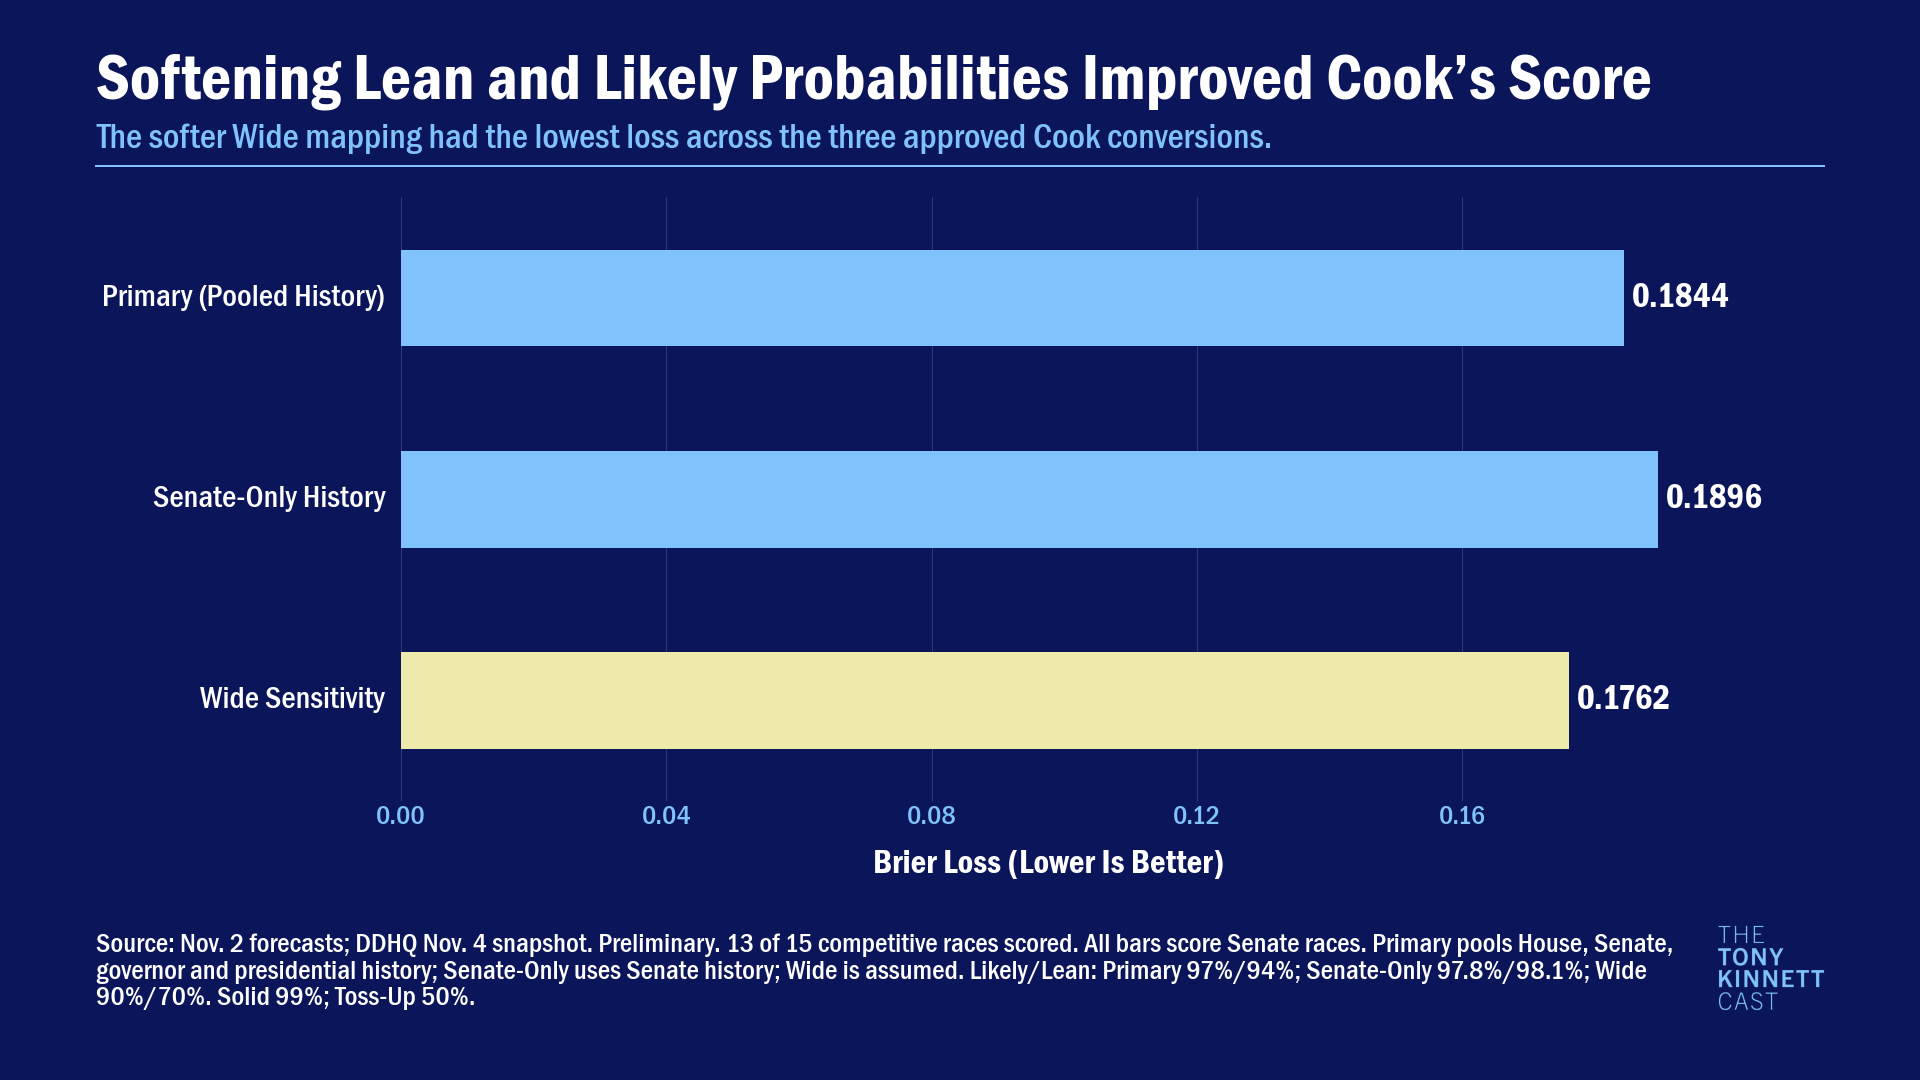

In [10]:
cook_scores, cook_skills, cook_pairs, cook_influence, cook_races, cook_calibration, cook_ranks = [], [], [], [], [], [], []
for sample in SAMPLES:
    frame = select_sample(full_frame, sample)
    primary_ranks = rank_cook_scores(frame, "primary")
    for mapping in ("primary", "senate", "wide"):
        cook = "p_cook_" + mapping
        ranks = rank_cook_scores(frame, mapping)
        for source, rank in ranks.items():
            cook_ranks.append({"sample": sample, "mapping": mapping, "source": source, "rank": rank,
                               "rank_change": rank - primary_ranks[source]})
        for metric, clip in (("brier", True), ("log", True), ("log", False)):
            cook_scores.append({"sample": sample, "mapping": mapping, "metric": metric, "clipped": metric == "log" and clip,
                                **probability_score(frame, cook, metric=metric, clip=clip).summary()})
        for source in [c for c in SOURCES if c != "p_cook_primary"] + [cook]:
            for reference in (cook, "p_constant", "p_uniform"):
                cook_skills.append({"sample": sample, "mapping": mapping, "source": source, "reference": reference,
                                    **brier_skill(frame, source, reference).summary()})
            if source == cook:
                continue
            for metric in ("brier", "log"):
                summary, rows, loo, draws = paired_analysis(frame, source, cook, metric=metric)
                cook_pairs.append({"sample": sample, "mapping": mapping, **summary})
                if len(loo):
                    cook_influence.append(loo.assign(sample=sample, mapping=mapping, first=source, second=cook, metric=metric))
                if len(rows):
                    detail = rows[["loss_first", "loss_second", "difference", "_weight"]].reset_index()
                    detail["contribution"] = detail.difference * detail._weight
                    cook_races.append(detail.assign(sample=sample, mapping=mapping, first=source, second=cook, metric=metric))
        cook_calibration.append(calibration(frame, cook, shared_latent, residual_latent).assign(sample=sample, mapping=mapping))
cook_scores = table("cook-scores", pd.DataFrame(cook_scores))
table("cook-skill", pd.DataFrame(cook_skills))
table("cook-paired", pd.DataFrame(cook_pairs))
cook_influence = table("cook-influence", pd.concat(cook_influence, ignore_index=True) if cook_influence else pd.DataFrame(), show=False)
if len(cook_influence):
    grouped = cook_influence.groupby(["sample", "mapping", "first", "metric"])
    bounds = grouped.agg(n_omissions=("race_id", "size"), minimum=("leave_one_out", "min"), maximum=("leave_one_out", "max"))
    bounds["max_absolute_change"] = grouped.change_from_full.apply(lambda x: x.abs().max())
    table("cook-influence-summary", bounds.reset_index())
table("cook-race-differences", pd.concat(cook_races, ignore_index=True) if cook_races else pd.DataFrame(), show=False)
table("cook-calibration", pd.concat(cook_calibration, ignore_index=True))
cook_ranks = table("cook-ranks", pd.DataFrame(cook_ranks))
changed = cook_ranks.loc[cook_ranks.rank_change.notna() & cook_ranks.rank_change.ne(0)]
display(Markdown(f"**Rank changes relative to primary mapping:** {len(changed)} source/sample/mapping entries. Ties retained."))

if primary.n_eligible:
    d = cook_scores.query("sample == 'non_solid' and metric == 'brier'").copy()
    d["label"] = d.mapping.map({"primary": "Primary (Pooled History)", "senate": "Senate-Only History", "wide": "Wide Sensitivity"})
    d["ink"] = np.where(d.mapping.eq("wide"), "#EEEAAC", colors["cook"])
    losses = d.set_index("mapping").value
    title = ("Softening Lean and Likely Probabilities Improved Cook’s Score" if losses["wide"] < min(losses["primary"], losses["senate"]) else
             "Cook’s Score Changes with the Probability Mapping")
    subtitle = ("The softer Wide mapping had the lowest loss across the three approved Cook conversions."
                if losses["wide"] < min(losses["primary"], losses["senate"]) else
                "Three approved mappings convert Cook ratings to probabilities on the same eligible races.")
    bar_chart("08-cook-mappings", title, subtitle, d, label="label", value="value", color="ink",
              note=coverage_note + "All bars score Senate races. Primary pools House, Senate, governor and presidential history; Senate-Only uses Senate history; Wide is assumed. Likely/Lean: Primary 97%/94%; Senate-Only 97.8%/98.1%; Wide 90%/70%. Solid 99%; Toss-Up 50%.")


## 8. Power note

These simulations generate outcomes from the fixed Economist/VoteHub mean, not from an estimated true model. They use 20,000 draws, seed 20261105 and the same latent dependence grid. Planned 35/15-race designs include pending races as simulated events, never as scored observations; eligible designs show current coverage separately.

Expected Kalshi-minus-mean Brier difference equals the average squared probability gap under this model. Approximate 80%-power detectable differences are `(Φ⁻¹(.975)+Φ⁻¹(.80)) × SD`, assuming a two-sided 5% normal test and treating simulated spread as fixed. They are design heuristics, not achieved-power claims or dependence-adjusted significance tests. Compare recalculated values with the plan's rounded independence approximations; dependence can enlarge the spread substantially.

,sample,design,n,rho_latent,expected_gap,simulated_mean,sd,detectable_gap_80pct,status,snapshot,synthetic
0,all,planned,35,0.00,0.003976,0.003930,0.009172,0.025697,conditional sensitivity,ddhq-20261104-222052-est,False
1,all,planned,35,0.10,0.003976,0.003904,0.011179,0.031318,conditional sensitivity,ddhq-20261104-222052-est,False
2,all,planned,35,0.25,0.003976,0.003860,0.013631,0.038189,conditional sensitivity,ddhq-20261104-222052-est,False
3,all,planned,35,0.50,0.003976,0.003841,0.016971,0.047546,conditional sensitivity,ddhq-20261104-222052-est,False
4,all,eligible,33,0.00,0.003699,0.003671,0.009088,0.025460,conditional sensitivity,ddhq-20261104-222052-est,False
5,all,eligible,33,0.10,0.003699,0.003656,0.010751,0.030121,conditional sensitivity,ddhq-20261104-222052-est,False
6,all,eligible,33,0.25,0.003699,0.003592,0.012860,0.036029,conditional sensitivity,ddhq-20261104-222052-est,False
7,all,eligible,33,0.50,0.003699,0.003581,0.015764,0.044163,conditional sensitivity,ddhq-20261104-222052-est,False
8,non_solid,planned,15,0.00,0.007876,0.007766,0.021217,0.059442,conditional sensitivity,ddhq-20261104-222052-est,False
9,non_solid,planned,15,0.10,0.007876,0.007709,0.025498,0.071435,conditional sensitivity,ddhq-20261104-222052-est,False


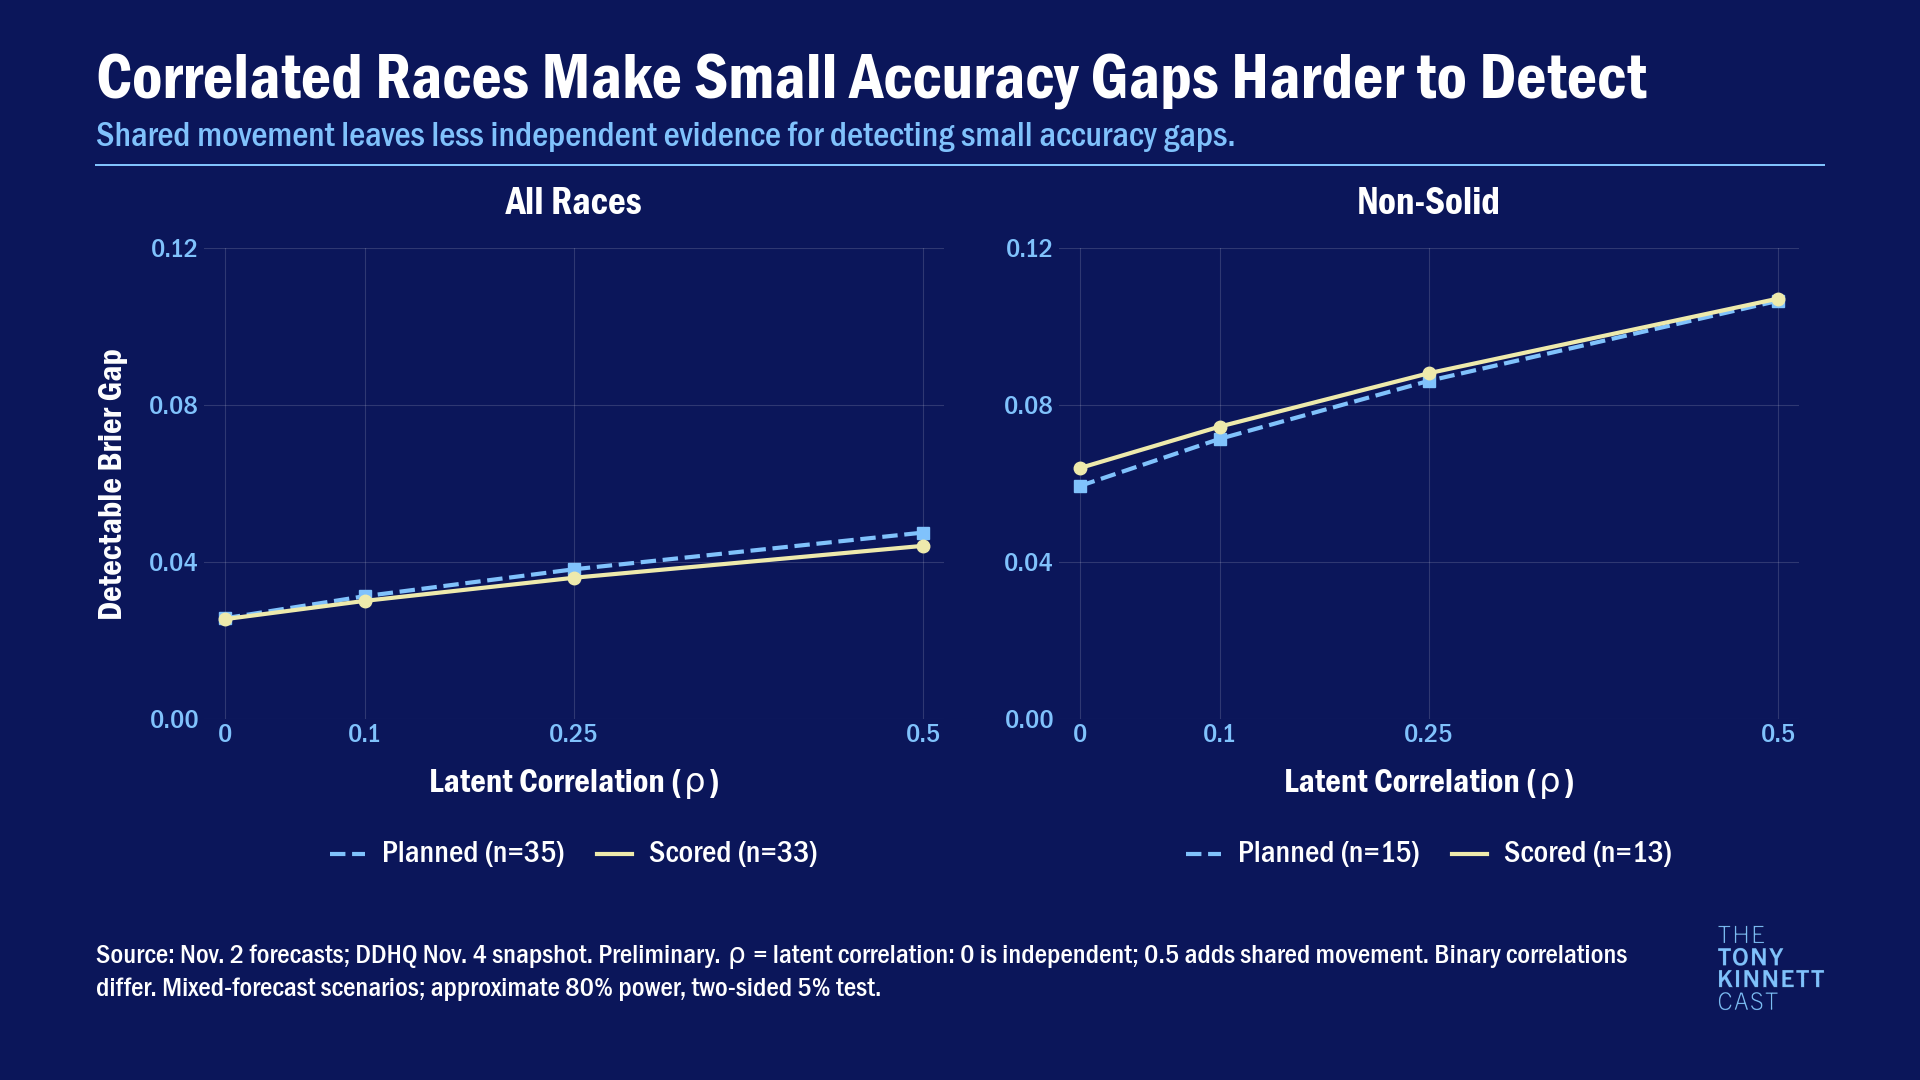

In [11]:
power_records = []
for sample in ("all", "non_solid"):
    planned = select_sample(full_frame, sample)
    for design, frame in (("planned", planned), ("eligible", match_sample(planned, ["p_kalshi", "p_model_mean"]).rows)):
        if frame.empty:
            power_records.append({"sample": sample, "design": design, "n": 0, "status": "unavailable"})
            continue
        k, p = frame.p_kalshi.to_numpy(), frame.p_model_mean.to_numpy()
        positions = full_frame.index.get_indexer(frame.index)
        for rho in RHOS:
            y = copula_outcomes(p, rho, shared_latent, residual_latent[:, positions])
            gaps = ((y - k) ** 2 - (y - p) ** 2).mean(axis=1)
            sd = float(gaps.std(ddof=1))
            power_records.append({"sample": sample, "design": design, "n": len(frame), "rho_latent": rho,
                                  "expected_gap": float(np.mean((k - p) ** 2)), "simulated_mean": float(gaps.mean()),
                                  "sd": sd, "detectable_gap_80pct": (NormalDist().inv_cdf(.975) + NormalDist().inv_cdf(.8)) * sd,
                                  "status": "conditional sensitivity"})
power = table("power", pd.DataFrame(power_records))

power_chart(power)


## Interpretation and limitations

Read the primary realized difference with its eligible count, influential races, conditional bootstrap range, and assumption-qualified sign-flip result. Secondary tables and exploratory longshot checks do not establish winners. Kalshi is one market; VoteHub Complete is market-informed, and no Legacy forecasts were collected. One national election cannot establish comparative performance across environments.

Unresolved inputs remain visible: pending AK/MS calls, unknown recount status, incomplete vote-share and ranked-choice compatibility evidence, incomplete source-specific forecast timing, unknown Kalshi price/volume measures, and the KY contract identity issue. Senate caucus seats/control remain a separate evidence and methodology task. This notebook does not change those gates. Synthetic complete results exercise software only and cannot be published.

In [12]:
if primary.n_eligible:
    comparison = pairs.query("sample == 'non_solid' and first == 'p_kalshi' and second == 'p_model_mean' and metric == 'brier'").iloc[0]
    display(Markdown(f"**Primary finding ({primary.n_eligible}/{primary.n_planned} eligible):** Kalshi minus the mixed mean is {primary.value:+.6f} Brier, with a conditional paired-bootstrap 95% range [{comparison.low:+.6f}, {comparison.high:+.6f}]. The exact sign-flip tail proportion is {flip['p_two_sided']:.6f} over {flip['n_nonzero']} nonzero pairs; symmetry and cross-race independence are assumptions, not established facts."))
    loo = influences.query("sample == 'non_solid' and first == 'p_kalshi' and second == 'p_model_mean' and metric == 'brier'")
    if len(loo):
        largest = loo.loc[loo.change_from_full.abs().idxmax()]
        display(Markdown(f"Dropping **{largest.race_id}** changes the primary estimate most ({largest.change_from_full:+.6f}). Leave-one-out estimates span [{loo.leave_one_out.min():+.6f}, {loo.leave_one_out.max():+.6f}]; this is influence, not an interval."))
    raw = scores.query("sample == 'non_solid' and metric == 'brier' and source == 'Kalshi'").iloc[0]
    normalized = scores.query("sample == 'non_solid' and metric == 'brier' and source == 'Kalshi normalized sensitivity'").iloc[0]
    display(Markdown(f"Normalizing Kalshi A/(A+B) changes its competitive-sample Brier by {normalized.value - raw.value:+.6f}. The raw analysis remains primary."))
    independent = power.query("sample == 'non_solid' and design == 'planned' and rho_latent == 0").iloc[0]
    dependent = power.query("sample == 'non_solid' and design == 'planned' and rho_latent == .5").iloc[0]
    display(Markdown(f"For the planned 15-race design, simulated gap SD rises from {independent.sd:.5f} at latent ρ=0 to {dependent.sd:.5f} at ρ=.5. Approximate detectable gaps rise from {independent.detectable_gap_80pct:.5f} to {dependent.detectable_gap_80pct:.5f}, versus conditional expected gap {independent.expected_gap:.5f}. These are model-conditional normal approximations."))

**Primary finding (13/15 eligible):** Kalshi minus the mixed mean is -0.042977 Brier, with a conditional paired-bootstrap 95% range [-0.077735, -0.010856]. The exact sign-flip tail proportion is 0.037842 over 13 nonzero pairs; symmetry and cross-race independence are assumptions, not established facts.

Dropping **KS-SEN** changes the primary estimate most (+0.009131). Leave-one-out estimates span [-0.050134, -0.033846]; this is influence, not an interval.

Normalizing Kalshi A/(A+B) changes its competitive-sample Brier by +0.000000. The raw analysis remains primary.

For the planned 15-race design, simulated gap SD rises from 0.02122 at latent ρ=0 to 0.03807 at ρ=.5. Approximate detectable gaps rise from 0.05944 to 0.10665, versus conditional expected gap 0.00788. These are model-conditional normal approximations.

In [13]:
analysis = {
    "snapshot": inputs.snapshot_id, "synthetic": inputs.manifest["synthetic"],
    "senate_timestamp": inputs.manifest["senate_timestamp"], "house_timestamp": inputs.manifest["house_timestamp"],
    "input_hashes": inputs.hashes, "graphics_assets": graphics_assets(), "symbol_fonts": SYMBOL_FONTS,
    "editable_source": f"notebooks/{PART}.ipynb", "figures": figure_records,
    "artifact_hashes": artifact_hashes,
    "settings": {"bootstrap_seed": BOOT_SEED, "bootstrap_replicates": BOOT_DRAWS,
                 "simulation_seed": SIM_SEED, "simulation_draws": SIM_DRAWS, "latent_correlations": RHOS},
    "primary": primary.summary(), "primary_sign_flip": flip,
}
(ctx.tables_dir / "analysis-provenance.json").write_text(json.dumps(analysis, indent=2) + "\n", encoding="utf-8");
print("Completed", PART, "for", inputs.snapshot_id, "with", len(figure_records), "lint-passing figures.")

Completed 02_forecast_accuracy for ddhq-20261104-222052-est with 8 lint-passing figures.
